# Tarea 7 · Optimización de Machine Learning, Explainable AI y Business Pitch

**Kevin Andrés Erazo Yepez — Aprendizaje Automático**  
**Dataset:** [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn).  
**Producto:** FaroCX · inteligencia comercial de retención.

Este notebook reproduce los requisitos en el orden del enunciado: preparación,
modelos, Grid Search, Random Search, Hyperband, NSGA-II, SHAP, LIME,
Streamlit y propuesta de negocio. Se conservan sin alterar las **33 celdas del
EDA original** de este mismo proyecto.

**Protocolo:** split 80/20 estratificado (seed 42), folds solo dentro de TRAIN,
selección por F1-CV y latencia predefinida, y TEST reservado para evaluación final.
Los resultados del conjunto de prueba **no** cambian la configuración elegida.
El umbral de clasificación es 0.50 y la clase positiva es `Churn=1`.


In [1]:
# Resolver el directorio de trabajo tanto desde la raíz como desde notebooks/.
import os, sys
from pathlib import Path
PROJECT = next((q for p in [Path.cwd(), *Path.cwd().parents] for q in [p]
                if (q / 'src' / 'core.py').is_file()), None)
if PROJECT is None:
    raise FileNotFoundError('Abre la carpeta V2 completa en VS Code: deben existir src/ y data/.')
os.chdir(PROJECT)
if str(PROJECT) not in sys.path: sys.path.insert(0, str(PROJECT))
print('Raíz del proyecto:', PROJECT)


Raíz del proyecto: /home/kevin-erazo/OneDrive/8) Octavo Semestre/Aprendizaje Automatico/7. Optimización de Machine Learning, Explainable AI y Business Pitch/V2


# Parte 1 · Exploratory Data Analysis (EDA)

El siguiente bloque corresponde al EDA original de esta conversación. Incluye
identificación de variables, auditoría de `TotalCharges`, balance de `Churn`,
exploración de entrenamiento y la especificación de `ColumnTransformer` y `Pipeline`.
El EDA no ajusta el preprocesador sobre el holdout.


# 01 · Análisis exploratorio de datos (EDA)
## Telco Customer Churn | Aprendizaje Automático

**Objetivo de negocio:** entender qué características describen a los clientes que abandonan la compañía (`Churn = Yes`) y evaluar si el dataset es adecuado para desarrollar una herramienta de priorización de retención.

**Alcance de este notebook:** carga, auditoría, limpieza justificada, balance de clases, análisis univariado y bivariado, prevención de *data leakage* y especificación de un preprocesamiento reproducible. **No se entrenan modelos, no se optimizan hiperparámetros y no se evalúa el conjunto de prueba en este notebook.**

**Fuente:** [Blastchar — Telco Customer Churn (Kaggle)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). Es un conjunto de datos de ejemplo difundido por IBM. Una fila representa a un cliente; `Churn` indica si abandonó el servicio. No se dispone de una secuencia temporal de capturas ni de resultados de campañas de retención.

### Protocolo metodológico

1. Auditar estructura, tipos, identificadores, nulos, duplicados e inconsistencias.
2. Aplicar únicamente correcciones deterministas y explicables que no aprendan estadísticas del dataset.
3. **Reservar el 20 % de prueba con partición estratificada y semilla fija.**
4. Hacer el EDA que relaciona predictores con `Churn` **solo sobre entrenamiento**.
5. Definir las transformaciones como `ColumnTransformer` + `Pipeline` **sin hacer `.fit()`** todavía.
6. Cerrar con una tabla de hallazgos, acciones y variables conservadas, generada con los datos realmente leídos.

> No confundir correlaciones o tasas por segmento con relaciones causales. El dataset sirve para una demostración de clasificación; no permite inferir por sí solo que una intervención vaya a evitar abandonos.

## 0. Entorno de ejecución

**Instalación sugerida (solo una vez, si faltan paquetes):**

```bash
pip install "kagglehub>=0.3" "pandas>=2.0" "numpy>=1.24" "matplotlib>=3.7" "seaborn>=0.12" "scikit-learn>=1.2" "ipython>=8" "jupyterlab>=4"
```

Si ejecutas en Google Colab, puedes usar `%pip install ...` en una celda. El notebook busca primero el CSV en `./data/` o en la carpeta actual; si no existe, lo descarga con la instrucción `kagglehub.dataset_download(...)` solicitada.

In [2]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

SEED = 42
TAMANO_TEST = 0.20
ARCHIVO_CSV = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 110)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)

print("Pandas:", pd.__version__)
print("Semilla:", SEED)

Pandas: 2.3.3
Semilla: 42


## 1. Carga y procedencia

No se sustituye el dataset por datos sintéticos ni se lee una fuente diferente de manera silenciosa. El archivo cargado se registra para facilitar la reproducibilidad. Si Kaggle cambia la versión, los conteos del análisis se calculan de nuevo y no se dan por supuestos.

In [3]:
rutas_locales = [Path("data") / ARCHIVO_CSV, Path(ARCHIVO_CSV)]
ruta_csv = next((r for r in rutas_locales if r.is_file()), None)

if ruta_csv is None:
    try:
        import kagglehub
    except ImportError as exc:
        raise ImportError(
            "No se encontró el CSV local y falta kagglehub. "
            "Instala kagglehub o coloca el archivo en ./data/."
        ) from exc
    path = kagglehub.dataset_download("blastchar/telco-customer-churn")
    candidatos = list(Path(path).rglob(ARCHIVO_CSV))
    if not candidatos:
        candidatos = list(Path(path).rglob("*.csv"))
    if len(candidatos) != 1:
        raise FileNotFoundError(
            f"Se esperaba un CSV único en {path}. Se encontraron: {candidatos}"
        )
    ruta_csv = candidatos[0]
else:
    path = str(ruta_csv.parent)

print("Path to dataset files:", path)
print("Archivo utilizado:", ruta_csv.resolve())

df_raw = pd.read_csv(ruta_csv, dtype={"customerID": "string"})
display(df_raw.head())
print(f"Dimensión original: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas")

Path to dataset files: data
Archivo utilizado: /home/kevin-erazo/OneDrive/8) Octavo Semestre/Aprendizaje Automatico/7. Optimización de Machine Learning, Explainable AI y Business Pitch/V2/data/WA_Fn-UseC_-Telco-Customer-Churn.csv


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dimensión original: 7,043 filas × 21 columnas


## 2. Diccionario de variables y tipología

El tipo de Pandas **no siempre es el tipo estadístico**: `SeniorCitizen` es un indicador categórico codificado con 0/1, mientras que `TotalCharges` debería ser numérica aunque aparezca originalmente como texto. La variable objetivo tampoco debe introducirse entre las variables predictoras.

- **Identificador:** `customerID` (único por cliente; no es una variable explicativa).
- **Objetivo:** `Churn` (binaria: `No` → 0, `Yes` → 1).
- **Numéricas (3):** `tenure`, `MonthlyCharges`, `TotalCharges`.
- **Categóricas (16):** las variables de perfil, contratación, servicios y método de pago que se enumeran en la próxima celda; se incluye `SeniorCitizen`.

No se impone una jerarquía ordinal artificial a `Contract`, `PaymentMethod`, `InternetService` ni a las categorías de servicios. Las categorías «No internet service» y «No phone service» aportan contexto y **no son valores faltantes**.

In [4]:
ID_COL = "customerID"
TARGET = "Churn"
NUMERICAS = ["tenure", "MonthlyCharges", "TotalCharges"]
CATEGORICAS = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService",
    "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
    "Contract", "PaperlessBilling", "PaymentMethod"
]
PREDICTORAS = NUMERICAS + CATEGORICAS
ESPERADAS = set([ID_COL, TARGET] + PREDICTORAS)

if set(df_raw.columns) != ESPERADAS:
    raise ValueError(
        "El esquema cambió. Revisar columnas inesperadas / ausentes antes de seguir. "
        f"Ausentes: {sorted(ESPERADAS - set(df_raw.columns))}; "
        f"adicionales: {sorted(set(df_raw.columns) - ESPERADAS)}"
    )

diccionario = pd.DataFrame({
    "Variable": df_raw.columns,
    "Rol": ["Identificador" if c == ID_COL else
            "Objetivo" if c == TARGET else
            "Numérica" if c in NUMERICAS else "Categórica" for c in df_raw.columns],
    "Tipo original": [str(df_raw[c].dtype) for c in df_raw.columns],
    "Valores distintos": [df_raw[c].nunique(dropna=True) for c in df_raw.columns],
    "Nulos Pandas (sin limpieza)": [int(df_raw[c].isna().sum()) for c in df_raw.columns]
})
display(diccionario)
print(f"Predictoras: {len(PREDICTORAS)} = {len(NUMERICAS)} numéricas + {len(CATEGORICAS)} categóricas")

,Variable,Rol,Tipo original,Valores distintos,Nulos Pandas (sin limpieza)
0,customerID,Identificador,string,7043,0
1,gender,Categórica,object,2,0
2,SeniorCitizen,Categórica,int64,2,0
3,Partner,Categórica,object,2,0
4,Dependents,Categórica,object,2,0
5,tenure,Numérica,int64,73,0
6,PhoneService,Categórica,object,2,0
7,MultipleLines,Categórica,object,3,0
8,InternetService,Categórica,object,3,0
9,OnlineSecurity,Categórica,object,3,0


Predictoras: 19 = 3 numéricas + 16 categóricas


## 3. Auditoría de calidad de datos

### 3.1. Espacios vacíos, coerción de tipos y duplicados

Para contar correctamente los faltantes, primero se eliminan espacios de los textos y los campos en blanco se marcan como `NaN`. `TotalCharges` se convierte con `pd.to_numeric(errors='coerce')`, registrando cuántos valores no pudieron convertirse. Se validan también duplicados exactos y duplicados por ID.

**Regla de filas:** no eliminar clientes por tener `TotalCharges` vacío. En este dataset, esos casos suelen tener `tenure = 0`: interpretamos que no existe todavía un importe histórico facturado y proponemos `TotalCharges = 0` **solo en ese supuesto**. Si aparecieran valores faltantes con `tenure > 0`, no se rellenarían con una media calculada sobre todo el dataset; quedarían para imputación dentro del pipeline ajustado en entrenamiento.

In [5]:
df = df_raw.copy(deep=True)

# Limpiar espacios en todas las columnas de tipo texto, sin convertir NaN a la cadena "nan".
for columna in df.select_dtypes(include=["object", "string"]).columns:
    df[columna] = df[columna].astype("string").str.strip()
    df[columna] = df[columna].replace("", pd.NA)

# Inspección antes de convertir: los espacios vacíos de TotalCharges ya son NaN.
blancos_totalcharges = int(df["TotalCharges"].isna().sum())
valores_originales_no_numericos = df["TotalCharges"].dropna()
valores_no_convertibles = int(pd.to_numeric(valores_originales_no_numericos, errors="coerce").isna().sum())

for columna in NUMERICAS:
    df[columna] = pd.to_numeric(df[columna], errors="coerce")

# Mantener SeniorCitizen como categoría semántica, no como magnitud continua.
valores_senior = set(df["SeniorCitizen"].dropna().astype("string").unique())
if not valores_senior.issubset({"0", "1"}):
    raise ValueError(f"SeniorCitizen tiene códigos inesperados: {valores_senior}")
df["SeniorCitizen"] = df["SeniorCitizen"].astype("string").map({"0": "No", "1": "Yes"})

# El target se convierte de forma explícita. Nunca se infiere a partir de LabelEncoder.
valores_churn = set(df[TARGET].dropna().unique())
if valores_churn != {"No", "Yes"} or df[TARGET].isna().any():
    raise ValueError(f"Etiquetas de Churn no válidas o incompletas: {valores_churn}")
df[TARGET] = df[TARGET].map({"No": 0, "Yes": 1}).astype("int8")

faltantes_antes = df.isna().sum().sort_values(ascending=False)
ids_duplicados = int(df[ID_COL].duplicated().sum())
filas_duplicadas = int(df.duplicated().sum())

print(f"Blancos originales en TotalCharges: {blancos_totalcharges}")
print(f"Textos no convertibles adicionales en TotalCharges: {valores_no_convertibles}")
print(f"IDs duplicados: {ids_duplicados}")
print(f"Filas completas duplicadas: {filas_duplicadas}")
display(faltantes_antes.rename("Nulos tras conversión").to_frame())

if ids_duplicados or filas_duplicadas:
    raise ValueError(
        "Se detectaron duplicados. Antes de dividir se debe revisar si son "
        "registros repetidos o múltiples capturas del mismo cliente; "
        "no se eliminan automáticamente."
    )

Blancos originales en TotalCharges: 11
Textos no convertibles adicionales en TotalCharges: 0
IDs duplicados: 0
Filas completas duplicadas: 0


,Nulos tras conversión
TotalCharges,11
gender,0
SeniorCitizen,0
Partner,0
customerID,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0


In [6]:
# Validar evidencia antes de decidir si la imputación de cero es apropiada.
faltan_total = df["TotalCharges"].isna()
mask_cero_justificado = faltan_total & df["tenure"].eq(0)
mask_sin_justificacion = faltan_total & ~df["tenure"].eq(0)

print("TotalCharges faltante y tenure=0:", int(mask_cero_justificado.sum()))
print("TotalCharges faltante y tenure!=0 (o desconocido):", int(mask_sin_justificacion.sum()))
display(df.loc[faltan_total, [ID_COL, "tenure", "MonthlyCharges", "TotalCharges", TARGET]].head(15))

# Decisión de dominio: no hay facturación histórica acumulada cuando la antigüedad es cero.
n_ceros_imputados = int(mask_cero_justificado.sum())
df.loc[mask_cero_justificado, "TotalCharges"] = 0.0

faltantes_despues = df.isna().sum().sort_values(ascending=False)
display(pd.DataFrame({
    "Antes de corrección": faltantes_antes,
    "Después de corrección": faltantes_despues
}).query('`Antes de corrección` > 0 or `Después de corrección` > 0'))
print("Filas eliminadas por faltantes:", 0)

TotalCharges faltante y tenure=0: 11
TotalCharges faltante y tenure!=0 (o desconocido): 0


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,<NA>,0
753,3115-CZMZD,0,20.25,<NA>,0
936,5709-LVOEQ,0,80.85,<NA>,0
1082,4367-NUYAO,0,25.75,<NA>,0
1340,1371-DWPAZ,0,56.05,<NA>,0
3331,7644-OMVMY,0,19.85,<NA>,0
3826,3213-VVOLG,0,25.35,<NA>,0
4380,2520-SGTTA,0,20.00,<NA>,0
5218,2923-ARZLG,0,19.70,<NA>,0
6670,4075-WKNIU,0,73.35,<NA>,0


,Antes de corrección,Después de corrección
TotalCharges,11,0


Filas eliminadas por faltantes: 0


### 3.2. Validaciones de coherencia

Se comprueban reglas lógicas entre servicios y la plausibilidad básica de importes y antigüedad. Los valores altos de gasto no se eliminan automáticamente como «outliers»: un cliente con permanencia larga puede tener un `TotalCharges` alto legítimo, y los clientes con facturas elevadas pueden ser precisamente relevantes para el negocio.

**Regla:** se reportan anomalías; si existen, se revisan antes de modelar. No se corrigen inventando servicios o importes.

In [7]:
servicios_internet = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies"
]

mask_phone_no_incoherente = df["PhoneService"].eq("No") & ~df["MultipleLines"].eq("No phone service")
mask_phone_si_incoherente = df["PhoneService"].eq("Yes") & df["MultipleLines"].eq("No phone service")
mask_internet_no_incoherente = df["InternetService"].eq("No") & (
    df[servicios_internet].ne("No internet service").any(axis=1)
)
mask_internet_si_incoherente = df["InternetService"].ne("No") & (
    df[servicios_internet].eq("No internet service").any(axis=1)
)

controles = {
    "tenure negativo": int(df["tenure"].lt(0).sum()),
    "MonthlyCharges negativo": int(df["MonthlyCharges"].lt(0).sum()),
    "TotalCharges negativo": int(df["TotalCharges"].lt(0).sum()),
    "Sin teléfono pero MultipleLines incoherente": int(mask_phone_no_incoherente.sum()),
    "Con teléfono pero MultipleLines='No phone service'": int(mask_phone_si_incoherente.sum()),
    "Sin internet pero servicios incoherentes": int(mask_internet_no_incoherente.sum()),
    "Con internet pero 'No internet service'": int(mask_internet_si_incoherente.sum()),
}
control_df = pd.Series(controles, name="Casos detectados").to_frame()
display(control_df)
print("Anomalías lógicas detectadas:", sum(controles.values()))

if sum(controles.values()) > 0:
    warnings.warn("Hay inconsistencias que deben revisarse antes de entrenar. No se corrigieron automáticamente.")

,Casos detectados
tenure negativo,0
MonthlyCharges negativo,0
TotalCharges negativo,0
Sin teléfono pero MultipleLines incoherente,0
Con teléfono pero MultipleLines='No phone service',0
Sin internet pero servicios incoherentes,0
Con internet pero 'No internet service',0


Anomalías lógicas detectadas: 0


## 4. Análisis de la variable objetivo y balance

La variable positiva es **`Churn = 1` (abandono)**. Un dataset no necesita tener exactamente 50/50 para ser útil, pero una mayoría clara de una clase vuelve engañosa la sola *Accuracy*. Se informa cantidad, porcentaje, relación mayoritaria/minoritaria y el rendimiento trivial que lograría un clasificador que siempre predijera «No abandona».

**Criterio descriptivo de este notebook:** denominaremos «desbalance moderado» a la distribución aproximada 3:1 de este dataset. No es un umbral universal y la decisión de reponderar clases será parte de la validación cruzada posterior.

,Clase,Clientes,Porcentaje (%)
0,No abandona (0),5174,73.46
1,Abandona (1),1869,26.54


Relación clase mayoritaria / minoritaria: 2.77:1
Accuracy del clasificador de mayoría: 73.46%
¿Equilibrio aproximado 50/50?: No


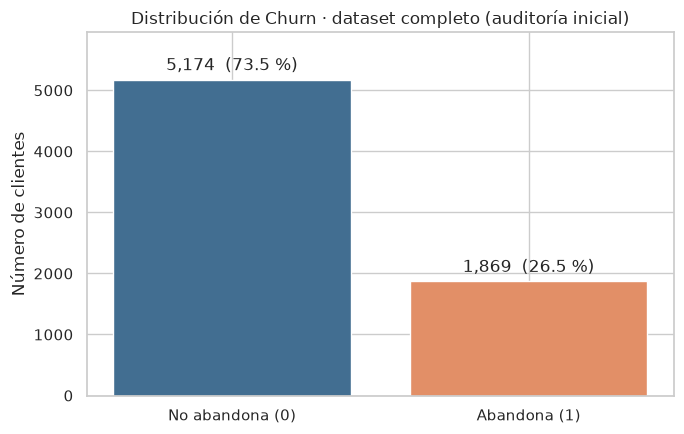

In [8]:
conteos_churn = df[TARGET].value_counts().reindex([0, 1], fill_value=0)
porcentajes_churn = 100 * conteos_churn / len(df)
balance_df = pd.DataFrame({
    "Clase": ["No abandona (0)", "Abandona (1)"],
    "Clientes": conteos_churn.values,
    "Porcentaje (%)": porcentajes_churn.values.round(2)
})
display(balance_df)

n_mayoritaria, n_minoritaria = int(conteos_churn.max()), int(conteos_churn.min())
relacion_clases = n_mayoritaria / n_minoritaria if n_minoritaria else np.inf
accuracy_trivial = n_mayoritaria / len(df)
print(f"Relación clase mayoritaria / minoritaria: {relacion_clases:.2f}:1")
print(f"Accuracy del clasificador de mayoría: {accuracy_trivial:.2%}")
print("¿Equilibrio aproximado 50/50?:", "Sí" if abs(porcentajes_churn[0] - porcentajes_churn[1]) < 10 else "No")

fig, ax = plt.subplots(figsize=(7, 4.5))
barras = ax.bar(balance_df["Clase"], balance_df["Clientes"], color=["#426e91", "#e28f67"])
ax.bar_label(barras, labels=[f"{n:,}  ({p:.1f} %)" for n, p in zip(balance_df["Clientes"], balance_df["Porcentaje (%)"])], padding=4)
ax.set(title="Distribución de Churn · dataset completo (auditoría inicial)", ylabel="Número de clientes", ylim=(0, n_mayoritaria*1.15))
plt.tight_layout()
plt.show()

## 5. Separación estratificada y aislamiento del test

**Punto crítico del proyecto:** la partición se realiza **antes de analizar la relación de las características con el abandono**. Usamos `stratify=df['Churn']`, `test_size=0.20` y `random_state=42`. Todos los gráficos de asociaciones a partir de este punto usan exclusivamente `df_train_eda`.

- No se ajustan imputadores, escaladores ni codificadores usando el test.
- No se eligen variables ni hiperparámetros observando el test.
- El `test` queda reservado para **una evaluación final** al terminar el entrenamiento, la optimización y la selección de modelo en notebooks posteriores.
- En las búsquedas futuras, cada `fit` de preprocesamiento debe ocurrir *dentro* de cada fold de validación cruzada.

> La comprobación de la distribución global de `Churn` y de problemas de calidad es una auditoría descriptiva. No se usan las relaciones entre variables y objetivo del conjunto de prueba para decidir el modelo.

In [9]:
idx_train, idx_test = train_test_split(
    df.index.to_numpy(),
    test_size=TAMANO_TEST,
    random_state=SEED,
    stratify=df[TARGET]
)

# Copias independientes, con índices originales para trazabilidad.
df_train_eda = df.loc[idx_train].copy()
df_test_reservado = df.loc[idx_test].copy()

X_train = df_train_eda[PREDICTORAS].copy()
y_train = df_train_eda[TARGET].copy()
X_test = df_test_reservado[PREDICTORAS].copy()
y_test = df_test_reservado[TARGET].copy()

assert set(X_train.index).isdisjoint(X_test.index), "¡Fuga: índices solapados!"
assert ID_COL not in X_train.columns and TARGET not in X_train.columns
assert len(df_train_eda) + len(df_test_reservado) == len(df)

print(f"Conjunto de entrenamiento / EDA: {len(X_train):,} filas, {X_train.shape[1]} predictoras")
print(f"Conjunto de prueba reservado: {len(X_test):,} filas (sin exploración del objetivo)")
print(f"Tasa Churn en entrenamiento: {y_train.mean():.2%}")

Conjunto de entrenamiento / EDA: 5,634 filas, 19 predictoras
Conjunto de prueba reservado: 1,409 filas (sin exploración del objetivo)
Tasa Churn en entrenamiento: 26.54%


## 6. EDA univariado: variables numéricas

Las tres numéricas no representan lo mismo: `tenure` mide meses de antigüedad, `MonthlyCharges` gasto mensual y `TotalCharges` cargos históricos acumulados. Por ello tienen escalas diferentes y podrían mostrar asimetría y valores extremos legítimos. La estandarización para regresión logística será una decisión del pipeline, **no una transformación calculada aquí con todo el dataset**.

,count,mean,std,min,25%,50%,75%,max,Nulos (train),Asimetría
tenure,5634.0,32.485091,24.568744,0.0,9.0,29.0,55.0,72.0,0,0.24
MonthlyCharges,5634.0,64.929961,30.138105,18.4,35.6625,70.5,90.0,118.75,0,-0.22
TotalCharges,5634.0,2299.334682,2279.204278,0.0,402.975,1394.925,3835.825,8684.8,0,0.95


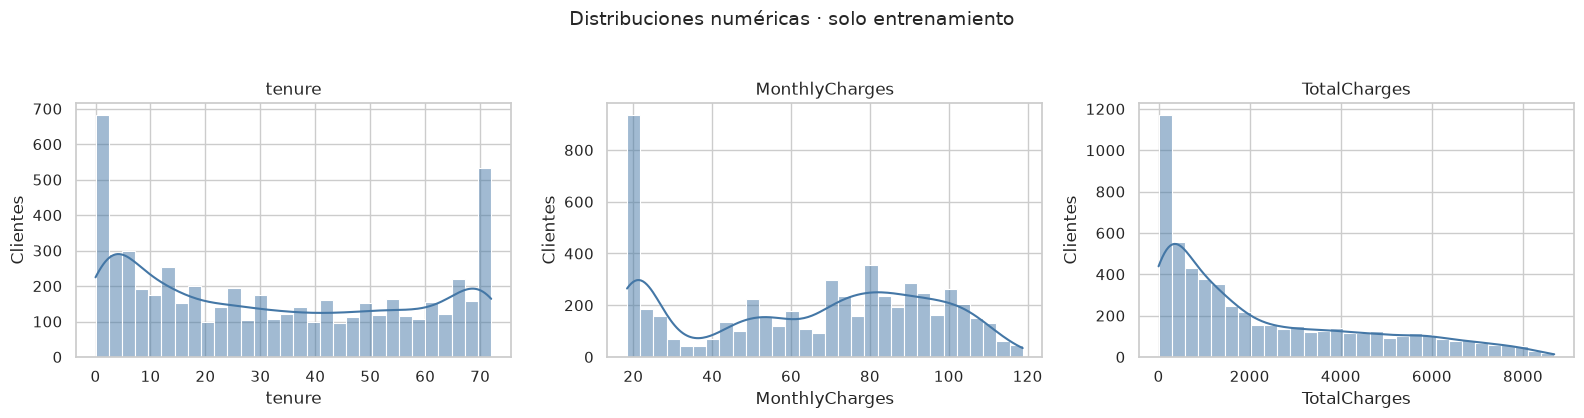

In [10]:
resumen_numericas = X_train[NUMERICAS].describe().T
resumen_numericas["Nulos (train)"] = X_train[NUMERICAS].isna().sum()
resumen_numericas["Asimetría"] = X_train[NUMERICAS].skew()
display(resumen_numericas.round(2))

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for ax, columna in zip(axs, NUMERICAS):
    sns.histplot(data=df_train_eda, x=columna, kde=True, ax=ax, color="#4477a6", bins=30)
    ax.set_title(columna)
    ax.set_ylabel("Clientes")
fig.suptitle("Distribuciones numéricas · solo entrenamiento", y=1.04, fontsize=14)
plt.tight_layout()
plt.show()

## 7. EDA univariado: variables categóricas

Se estudia el **número de categorías** de cada variable, posibles categorías raras y su proporción. Esto respalda la selección de `OneHotEncoder`, compatible con múltiples niveles nominales y con categorías desconocidas en inferencia. Una codificación numérica arbitraria (`0,1,2,...`) introduciría un orden no necesariamente existente.

,Variable,Niveles (train),Nulos (train),Categorías observadas (train)
0,gender,2,0,"Female, Male"
1,SeniorCitizen,2,0,"No, Yes"
2,Partner,2,0,"No, Yes"
3,Dependents,2,0,"No, Yes"
4,PhoneService,2,0,"No, Yes"
5,MultipleLines,3,0,"No, No phone service, Yes"
6,InternetService,3,0,"DSL, Fiber optic, No"
7,OnlineSecurity,3,0,"No, No internet service, Yes"
8,OnlineBackup,3,0,"No, No internet service, Yes"
9,DeviceProtection,3,0,"No, No internet service, Yes"


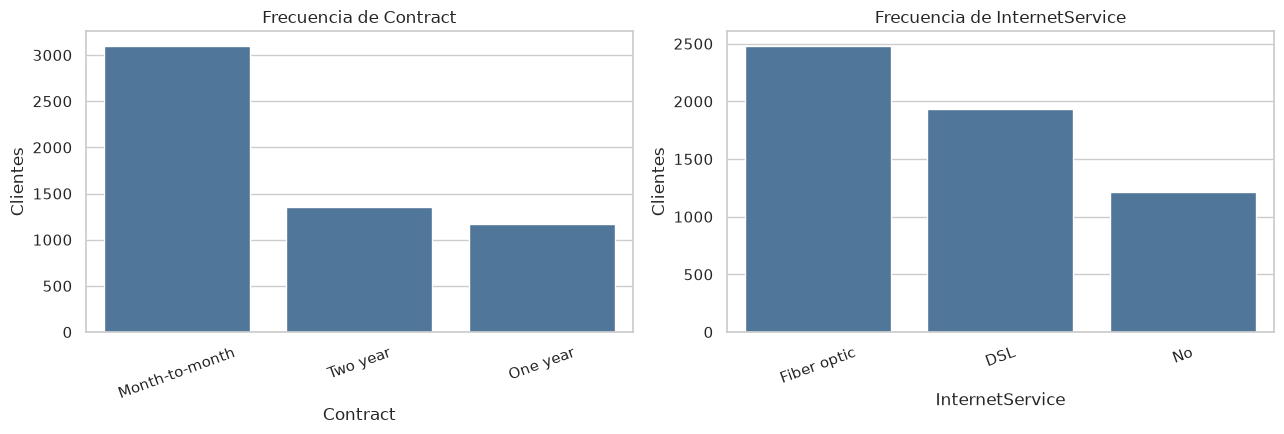

In [11]:
resumen_categoricas = pd.DataFrame({
    "Variable": CATEGORICAS,
    "Niveles (train)": [X_train[c].nunique(dropna=True) for c in CATEGORICAS],
    "Nulos (train)": [int(X_train[c].isna().sum()) for c in CATEGORICAS],
    "Categorías observadas (train)": [", ".join(sorted(X_train[c].dropna().astype(str).unique())) for c in CATEGORICAS],
})
display(resumen_categoricas)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col in zip(axs, ["Contract", "InternetService"]):
    orden = X_train[col].value_counts().index
    sns.countplot(data=df_train_eda, x=col, order=orden, ax=ax, color="#4477a6")
    ax.set(title=f"Frecuencia de {col}", xlabel=col, ylabel="Clientes")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 8. EDA bivariado: categorías y tasa de abandono

Comparar *conteos* únicamente puede confundir tamaño del segmento con riesgo. Para cada categoría calculamos la **tasa de churn dentro del segmento** (`clientes que abandonan / clientes del segmento`). Se muestra también el tamaño de cada grupo para no sobreinterpretar categorías pequeñas.

Se destacan `Contract`, `InternetService`, `PaymentMethod` y `TechSupport` por su relevancia comercial y variedad de niveles. Estas relaciones son descriptivas y no demuestran causalidad; por ejemplo, el tipo de contrato puede asociarse a la antigüedad y a otros factores.

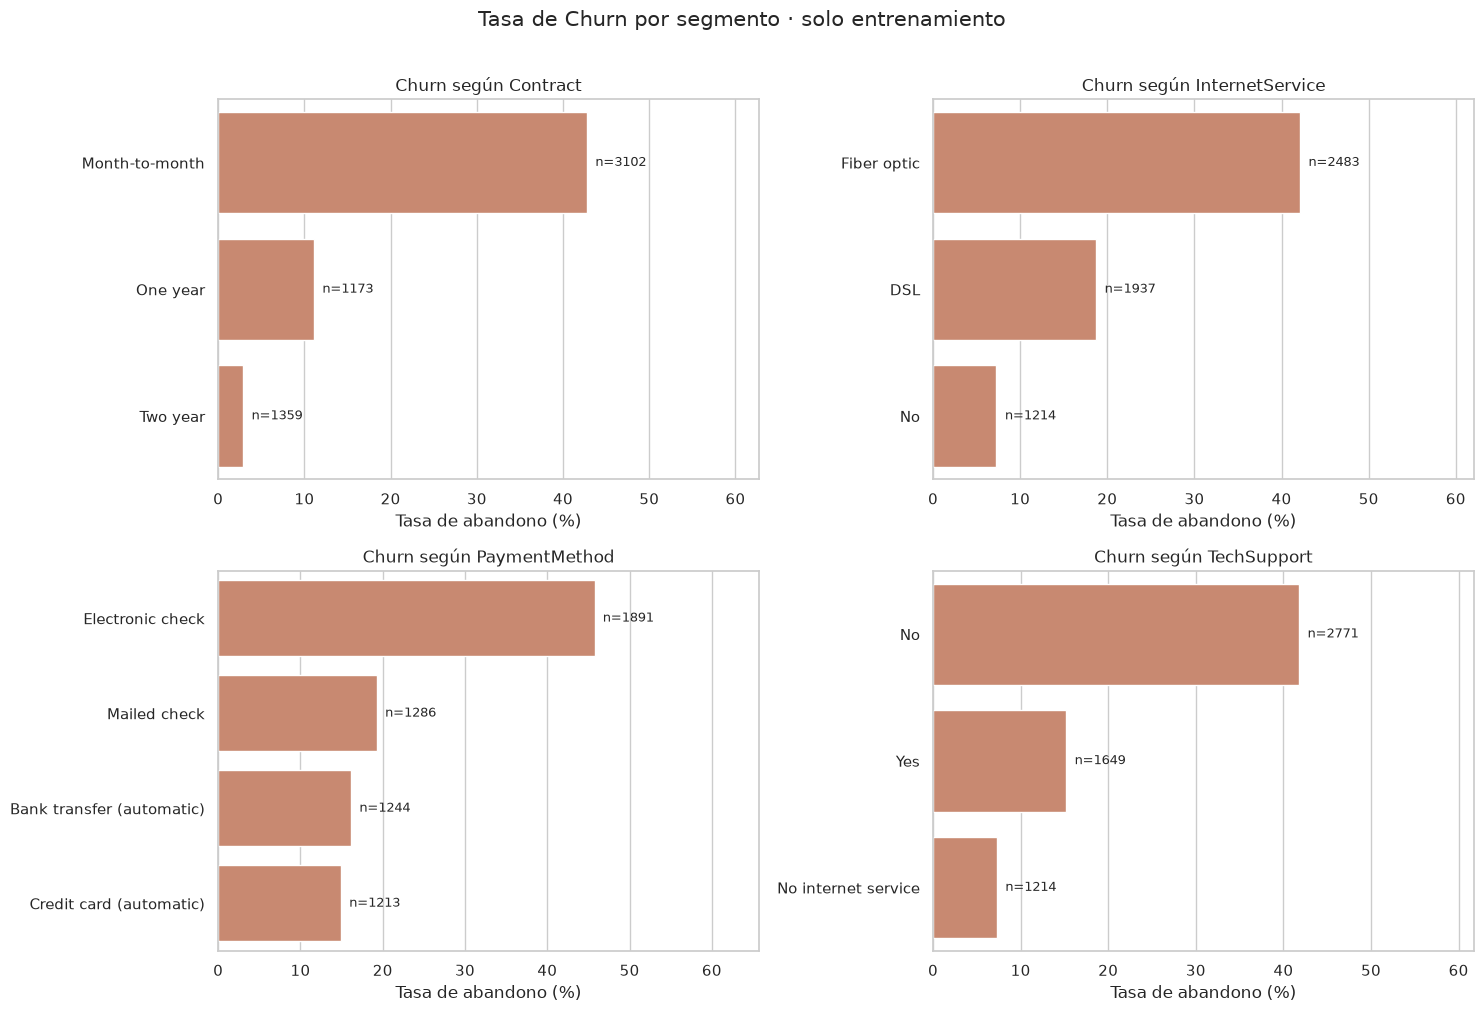


Contract


,Contract,clientes,abandonos,tasa_churn_pct
0,Month-to-month,3102,1326,42.75
1,One year,1173,130,11.08
2,Two year,1359,39,2.87



InternetService


,InternetService,clientes,abandonos,tasa_churn_pct
1,Fiber optic,2483,1045,42.09
0,DSL,1937,362,18.69
2,No,1214,88,7.25



PaymentMethod


,PaymentMethod,clientes,abandonos,tasa_churn_pct
2,Electronic check,1891,865,45.74
3,Mailed check,1286,248,19.28
0,Bank transfer (automatic),1244,201,16.16
1,Credit card (automatic),1213,181,14.92



TechSupport


,TechSupport,clientes,abandonos,tasa_churn_pct
0,No,2771,1157,41.75
2,Yes,1649,250,15.16
1,No internet service,1214,88,7.25


In [12]:
def tasa_por_segmento(datos, variable):
    resultado = (
        datos.groupby(variable, dropna=False)[TARGET]
        .agg(clientes="size", abandonos="sum", tasa_churn="mean")
        .reset_index()
        .sort_values("tasa_churn", ascending=False)
    )
    resultado["tasa_churn_pct"] = 100 * resultado["tasa_churn"]
    return resultado

variables_segmentos = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, variable in zip(axes.ravel(), variables_segmentos):
    tabla = tasa_por_segmento(df_train_eda, variable)
    sns.barplot(data=tabla, y=variable, x="tasa_churn_pct", ax=ax, color="#d68362", errorbar=None)
    ax.set(xlabel="Tasa de abandono (%)", ylabel="", title=f"Churn según {variable}", xlim=(0, 100))
    for i, fila in enumerate(tabla.itertuples(index=False)):
        ax.text(float(fila.tasa_churn_pct) + 1, i, f"n={int(fila.clientes)}", va="center", fontsize=9)
    ax.set_xlim(0, max(55, float(tabla["tasa_churn_pct"].max()) + 20))
plt.suptitle("Tasa de Churn por segmento · solo entrenamiento", y=1.01, fontsize=15)
plt.tight_layout()
plt.show()

for variable in variables_segmentos:
    print(f"\n{variable}")
    display(tasa_por_segmento(df_train_eda, variable)[[variable, "clientes", "abandonos", "tasa_churn_pct"]].round(2))

## 9. EDA bivariado: numéricas y abandono

Se comparan distribuciones por clase sin usar la partición de prueba. La asociación entre baja permanencia y churn (si aparece) puede indicar un segmento prioritario para campañas; diferencias de cargos pueden reflejar mezcla de planes. No se fijará ningún umbral manual de clasificación con estos gráficos.

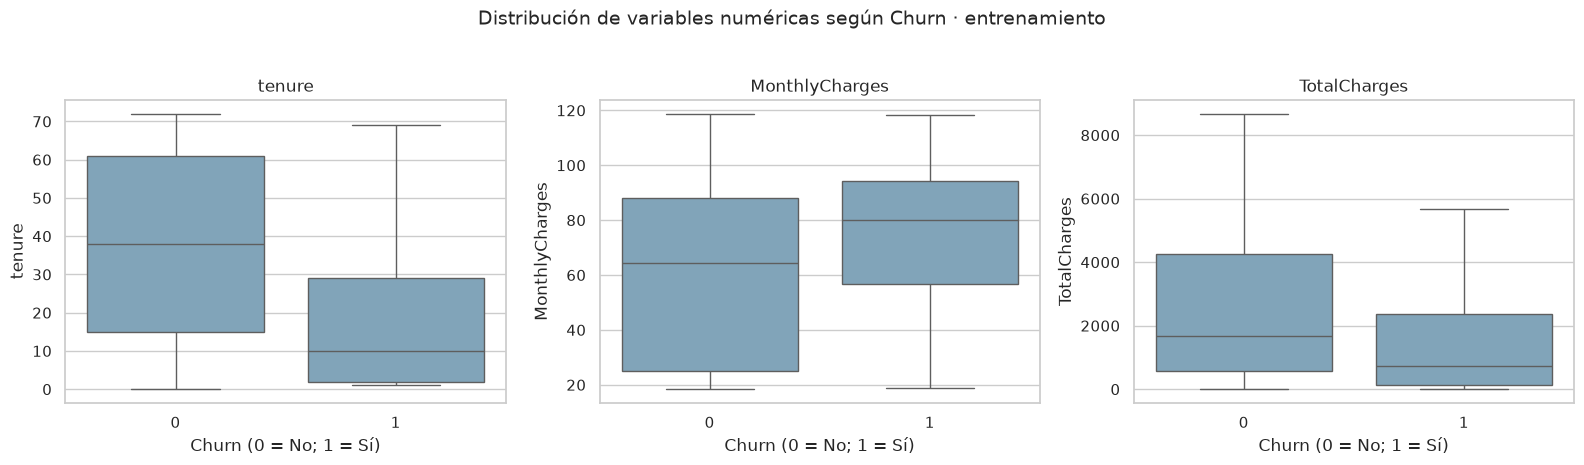

tenure        MonthlyCharges        TotalCharges         
      median   mean         median   mean       median     mean
Churn                                                          
0       38.0  37.59          64.40  61.34      1686.15  2564.72
1       10.0  18.36          79.95  74.86        740.3  1564.59

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, columna in zip(axes, NUMERICAS):
    sns.boxplot(
        data=df_train_eda, x=TARGET, y=columna,
        order=[0, 1], ax=ax, color="#78a6c2", showfliers=False
    )
    ax.set(xlabel="Churn (0 = No; 1 = Sí)", title=columna)
fig.suptitle("Distribución de variables numéricas según Churn · entrenamiento", y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

comparacion_numericas = df_train_eda.groupby(TARGET)[NUMERICAS].agg(["median", "mean"])
display(comparacion_numericas.round(2))

## 10. Correlación, redundancia y lectura comercial

La correlación de Pearson entre numéricas se utiliza como diagnóstico, **no como motivo automático para quitar una variable**. `TotalCharges` acumula montos a lo largo de la permanencia y puede ser redundante con `tenure` y `MonthlyCharges`; aun así, conviene mantenerla inicialmente y evaluar su aporte con validación cruzada.

**Posible riesgo temporal:** antes de desplegar el modelo hay que confirmar que `TotalCharges`, `tenure` y las demás variables se conocen **en el instante de la predicción**. Si alguna estuviera calculada después del abandono, habría fuga temporal de información. Este dataset de ejemplo no proporciona fechas suficientes para demostrarlo.

,tenure,MonthlyCharges,TotalCharges,Churn
tenure,1.000,0.257,0.830,-0.346
MonthlyCharges,0.257,1.000,0.654,0.198
TotalCharges,0.830,0.654,1.000,-0.194
Churn,-0.346,0.198,-0.194,1.000


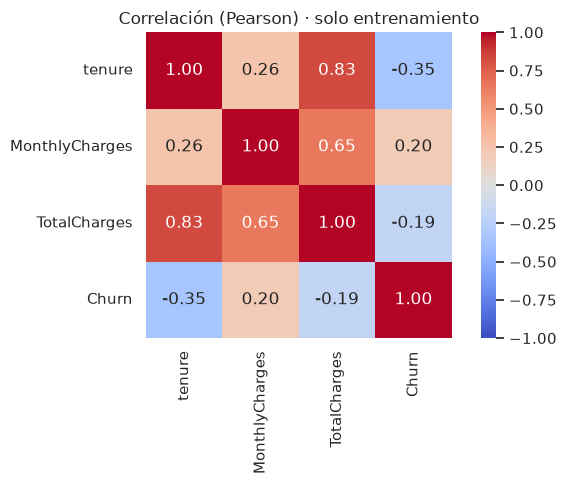

In [14]:
corr = df_train_eda[NUMERICAS + [TARGET]].corr(method="pearson")
display(corr.round(3))
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlación (Pearson) · solo entrenamiento")
plt.tight_layout()
plt.show()

## 11. Segmentación exploratoria para una futura propuesta de negocio

Una hipótesis comercial razonable es que **permanencia y nivel de factura mensual** pueden servir para priorizar una oferta de retención. Se explora una cuadrícula de segmentos, usando bandas analíticas del entrenamiento. No se incluyen estas columnas derivadas en el pipeline inicial: crear umbrales basados en cuantiles o métricas del dataset completo podría introducir decisiones difíciles de validar.

**Importante:** el análisis de segmentos solo muestra asociación; no estima ahorro económico, uplift causal ni efectividad real de campañas.

Tasa de Churn por segmento (entrenamiento):


Banda_cargo_mensual,Alto %,Bajo %,Medio %
Banda_antiguedad,,,
0–12,76.2,30.0,53.9
13–24,52.0,10.9,28.5
25–48,34.9,5.7,17.6
49+,15.4,3.1,6.1


Tamaño por segmento (entrenamiento):


Banda_cargo_mensual,Alto,Bajo,Medio
Banda_antiguedad,,,
0–12,303,761,673
13–24,223,293,302
25–48,473,403,414
49+,879,422,488


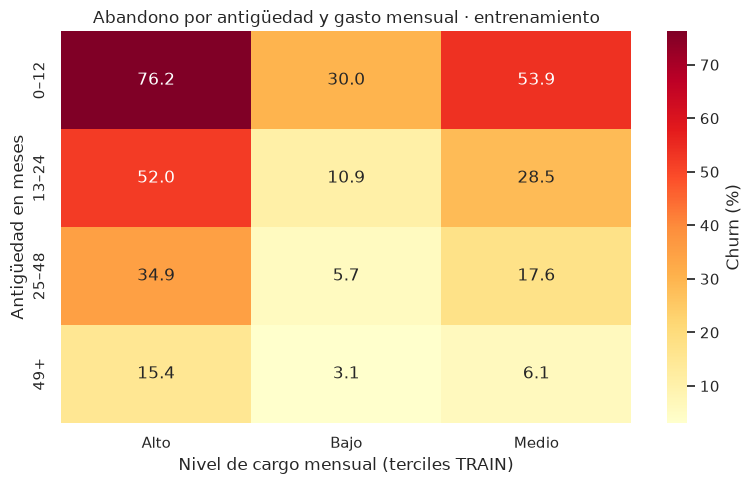

In [15]:
segmentado = df_train_eda[["tenure", "MonthlyCharges", TARGET]].copy()

# Bandas de antigüedad con cortes fijos interpretables, sin aprender del test.
segmentado["Banda_antiguedad"] = pd.cut(
    segmentado["tenure"], bins=[-1, 12, 24, 48, np.inf],
    labels=["0–12", "13–24", "25–48", "49+"], include_lowest=True
)

# Bandas descriptivas de mensualidad: usan cuantiles del TRAIN, no del test.
# Si los cuantiles coinciden, qcut elimina cortes redundantes de forma explícita.
segmentado["Banda_cargo_mensual"] = pd.qcut(
    segmentado["MonthlyCharges"], q=3, labels=False, duplicates="drop"
).map({0: "Bajo", 1: "Medio", 2: "Alto"})

pivot_riesgo = segmentado.pivot_table(
    index="Banda_antiguedad", columns="Banda_cargo_mensual",
    values=TARGET, aggfunc="mean", observed=True
)
pivot_tamanio = segmentado.pivot_table(
    index="Banda_antiguedad", columns="Banda_cargo_mensual",
    values=TARGET, aggfunc="size", observed=True
)

print("Tasa de Churn por segmento (entrenamiento):")
display((100 * pivot_riesgo).round(1).add_suffix(" %"))
print("Tamaño por segmento (entrenamiento):")
display(pivot_tamanio)

plt.figure(figsize=(8, 5))
sns.heatmap(100 * pivot_riesgo, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "Churn (%)"})
plt.title("Abandono por antigüedad y gasto mensual · entrenamiento")
plt.xlabel("Nivel de cargo mensual (terciles TRAIN)")
plt.ylabel("Antigüedad en meses")
plt.tight_layout()
plt.show()

## 12. Decisión de preprocesamiento para la siguiente fase

| Grupo | Acción propuesta | Justificación |
|---|---|---|
| `customerID` | **Excluir de `X`**, conservar en la auditoría | Identificador sin semántica predictiva; puede favorecer memorización. |
| `Churn` | Convertir `Yes` → 1 y `No` → 0; separar como `y` | Clasificación binaria, clase positiva = abandono. |
| `tenure`, `MonthlyCharges`, `TotalCharges` | `SimpleImputer(strategy='median')` + `StandardScaler()` dentro del pipeline | Robustez ante faltantes futuros y escalas diferentes; útil para regresión logística y SVM. `TotalCharges` ya recibió la corrección determinista de `tenure=0`. |
| 16 categóricas (incluye `SeniorCitizen`) | `SimpleImputer(strategy='most_frequent')` + `OneHotEncoder(handle_unknown='ignore')` | Evita orden arbitrario, conserva «No internet service» como categoría, acepta categorías nuevas al desplegar. |
| Filas con `TotalCharges` faltante y `tenure=0` | **Conservar** e imputar `TotalCharges=0` | Regla de negocio explícita, aplicada fila a fila y sin estadísticas globales. |
| Outliers numéricos | No eliminar de manera automática | Los gastos grandes y antigüedades largas pueden ser casos válidos. |
| Desbalance de `Churn` | Estratificar; evaluar `class_weight` en CV | Evita considerar como buen modelo a uno que siempre prediga «No». No aplicar SMOTE antes del split. |

**Por qué OHE y no `LabelEncoder`/codificación ordinal:** `Contract` y `PaymentMethod` no son niveles de una magnitud continua; una codificación 0–1–2–3 introduciría distancias inexistentes. Con aproximadamente dieciséis variables nominales de baja cardinalidad, OHE es viable. `SeniorCitizen` se expresa como «Yes/No» por consistencia semántica. Se conserva el conjunto completo de *dummies* para facilitar trazabilidad hacia SHAP y LIME; una regresión logística regularizada maneja la redundancia resultante.

**Atención:** el escalado es importante en modelos sensibles a magnitudes (Logistic Regression, SVM). Random Forest no lo necesita, pero se puede usar un preprocesamiento común para una comparación controlada. El uso de `OneHotEncoder(sparse_output=False)` es asequible para este dataset pequeño; en uno grande convendría salida dispersa.

In [16]:
# ESPECIFICACIÓN, SIN FIT: no se aprende nada de los folds ni del holdout.
pipeline_numerico = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler())
])

pipeline_categorico = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocesador = ColumnTransformer(transformers=[
    ("num", pipeline_numerico, NUMERICAS),
    ("cat", pipeline_categorico, CATEGORICAS)
], remainder="drop", verbose_feature_names_out=True)

print("ColumnTransformer definido, NO ajustado.")
print("Numéricas:", NUMERICAS)
print("Categóricas:", CATEGORICAS)
print("Para la fase 2: Pipeline([('prep', preprocesador), ('modelo', clasificador)])")
print("Usar StratifiedKFold y búsqueda de hiperparámetros SOLO sobre X_train / y_train.")

ColumnTransformer definido, NO ajustado.
Numéricas: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categóricas: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Para la fase 2: Pipeline([('prep', preprocesador), ('modelo', clasificador)])
Usar StratifiedKFold y búsqueda de hiperparámetros SOLO sobre X_train / y_train.


## 13. Conclusiones del EDA (generadas con los datos de ejecución)

La siguiente celda crea la **tabla final de diagnóstico y decisiones**. Distingue entre columnas originales y predictoras, conserva el recuento real de nulos corregidos, registra las filas descartadas y documenta cómo se tratarán las variables. Los conteos se calculan dinámicamente: no dependen de copiar cifras de una solución externa.

In [17]:
# Resumen de relaciones observadas SOLO en entrenamiento.
tasas_contrato = tasa_por_segmento(df_train_eda, "Contract")
segmento_contrato_mayor = tasas_contrato.iloc[0]
segmento_contrato_menor = tasas_contrato.iloc[-1]

faltantes_pendientes = int(df[PREDICTORAS].isna().sum().sum())
num_fil_originales = len(df_raw)
num_fil_finales = len(df)
num_cols_originales = df_raw.shape[1]
num_cols_finales = len(PREDICTORAS) + 1

resumen_decisiones = pd.DataFrame([
    ("Fuente", "blastchar/telco-customer-churn", "Archivo Kaggle identificado; carga reproducible"),
    ("Dimensión original", f"{num_fil_originales:,} filas × {num_cols_originales} columnas", "Auditar estructura antes de transformar"),
    ("Variable objetivo", "Churn: 0 = No, 1 = Yes", "Clasificación binaria; abandono es clase positiva"),
    ("Distribución de Churn", f"No: {conteos_churn[0]:,} ({porcentajes_churn[0]:.2f} %); Sí: {conteos_churn[1]:,} ({porcentajes_churn[1]:.2f} %)", "Desbalance de clases: preservar mediante estratificación"),
    ("Relación de clases", f"{relacion_clases:.2f}:1 (mayoritaria/minoritaria)", "Accuracy sola sería insuficiente; priorizar Recall, F1, ROC-AUC y Precision"),
    ("Baseline de mayoría", f"Accuracy = {accuracy_trivial:.2%}", "Una mejora debe superar la regla trivial sin ignorar la clase 1"),
    ("Identificador", ID_COL, "Se mantiene para trazabilidad; se EXCLUYE de X"),
    ("Variables numéricas", f"{len(NUMERICAS)}: {', '.join(NUMERICAS)}", "Imputación mediana y escalado aprendidos solo en train/folds"),
    ("Variables categóricas", f"{len(CATEGORICAS)} (incluye SeniorCitizen)", "Imputación modal y OneHotEncoder con handle_unknown='ignore'"),
    ("TotalCharges blanco", f"{blancos_totalcharges} espacios vacíos; {valores_no_convertibles} errores adicionales", "Se convirtió a numérico y se diagnosticaron faltantes"),
    ("Ceros de TotalCharges imputados", f"{n_ceros_imputados} casos con tenure=0", "Corrección de dominio específica, sin eliminar clientes"),
    ("Faltantes de predictores restantes", str(faltantes_pendientes), "Si existieran, se tratarían DENTRO del pipeline"),
    ("Duplicados", f"{ids_duplicados} IDs; {filas_duplicadas} filas completas", "No se encontraron duplicados por resolver si ambos son 0"),
    ("Inconsistencias de servicio", f"{sum(controles.values())} incidencias de los controles aplicados", "No modificar automáticamente; revisar si aparecen"),
    ("Filas eliminadas", str(num_fil_originales - num_fil_finales), "No descartar filas por TotalCharges vacío cuando tenure=0"),
    ("Columnas excluidas del modelo", ID_COL, "No usar identificadores ni Churn como predictores"),
    ("Datos preparados", f"{num_fil_finales:,} filas × {num_cols_finales} columnas (19 X + 1 y)", "Conservar todas las variables predictoras iniciales"),
    ("Partición protegida", f"Train: {len(X_train):,} | Test: {len(X_test):,} (80/20 estratificado)", "Test reservado hasta evaluación final del modelo"),
    ("Mayor tasa de churn por contrato (train)", f"{segmento_contrato_mayor['Contract']}: {segmento_contrato_mayor['tasa_churn_pct']:.1f} % (n={int(segmento_contrato_mayor['clientes'])})", "Hipótesis de segmentación, NO causalidad"),
    ("Menor tasa de churn por contrato (train)", f"{segmento_contrato_menor['Contract']}: {segmento_contrato_menor['tasa_churn_pct']:.1f} % (n={int(segmento_contrato_menor['clientes'])})", "Verificar estabilidad con futuras validaciones"),
    ("Outliers", "Ninguna eliminación automática", "Importes y antigüedades altos pueden ser reales"),
    ("Estado del preprocesador", "Definido, no entrenado", "Ajustar el pipeline dentro de cada fold de validación cruzada"),
    ("Riesgo de leakage", "Temporalidad de variables no verificable en dataset de ejemplo", "Validar disponibilidad de variables al predecir y NO analizar test"),
], columns=["Aspecto", "Resultado observado", "Decisión y justificación"])

display(Markdown("### Tabla resumen final del EDA"))
display(resumen_decisiones)

display(Markdown("### Variables con las que continuaremos"))
variables_finales = pd.DataFrame([
    {"Variable": c,
     "Tipo para modelado": "Numérica" if c in NUMERICAS else "Categórica",
     "Nulos pendientes en dataset limpio": int(df[c].isna().sum()),
     "Conservada": "Sí",
     "Tratamiento previsto": "Mediana + StandardScaler" if c in NUMERICAS else "Moda + OneHotEncoder"}
    for c in PREDICTORAS
])
display(variables_finales)

display(Markdown(
    f"**Resultado:** {len(PREDICTORAS)} predictores ({len(NUMERICAS)} numéricos y "
    f"{len(CATEGORICAS)} categóricos), {len(df):,} clientes, "
    f"{len(X_train):,} para desarrollo y {len(X_test):,} reservados para prueba. "
    "No se ha entrenado ni ajustado ningún modelo o transformador."
))

### Tabla resumen final del EDA

,Aspecto,Resultado observado,Decisión y justificación
0,Fuente,blastchar/telco-customer-churn,Archivo Kaggle identificado; carga reproducible
1,Dimensión original,"7,043 filas × 21 columnas",Auditar estructura antes de transformar
2,Variable objetivo,"Churn: 0 = No, 1 = Yes",Clasificación binaria; abandono es clase positiva
3,Distribución de Churn,"No: 5,174 (73.46 %); Sí: 1,869 (26.54 %)",Desbalance de clases: preservar mediante estratificación
4,Relación de clases,2.77:1 (mayoritaria/minoritaria),"Accuracy sola sería insuficiente; priorizar Recall, F1, ROC-AUC y Precision"
5,Baseline de mayoría,Accuracy = 73.46%,Una mejora debe superar la regla trivial sin ignorar la clase 1
6,Identificador,customerID,Se mantiene para trazabilidad; se EXCLUYE de X
7,Variables numéricas,"3: tenure, MonthlyCharges, TotalCharges",Imputación mediana y escalado aprendidos solo en train/folds
8,Variables categóricas,16 (incluye SeniorCitizen),Imputación modal y OneHotEncoder con handle_unknown='ignore'
9,TotalCharges blanco,11 espacios vacíos; 0 errores adicionales,Se convirtió a numérico y se diagnosticaron faltantes


### Variables con las que continuaremos

,Variable,Tipo para modelado,Nulos pendientes en dataset limpio,Conservada,Tratamiento previsto
0,tenure,Numérica,0,Sí,Mediana + StandardScaler
1,MonthlyCharges,Numérica,0,Sí,Mediana + StandardScaler
2,TotalCharges,Numérica,0,Sí,Mediana + StandardScaler
3,gender,Categórica,0,Sí,Moda + OneHotEncoder
4,SeniorCitizen,Categórica,0,Sí,Moda + OneHotEncoder
5,Partner,Categórica,0,Sí,Moda + OneHotEncoder
6,Dependents,Categórica,0,Sí,Moda + OneHotEncoder
7,PhoneService,Categórica,0,Sí,Moda + OneHotEncoder
8,MultipleLines,Categórica,0,Sí,Moda + OneHotEncoder
9,InternetService,Categórica,0,Sí,Moda + OneHotEncoder


**Resultado:** 19 predictores (3 numéricos y 16 categóricos), 7,043 clientes, 5,634 para desarrollo y 1,409 reservados para prueba. No se ha entrenado ni ajustado ningún modelo o transformador.

## 14. Puente hacia el proyecto completo (próximos notebooks)

**No ejecutar estas etapas sobre `X_test` todavía.** Este EDA deja disponibles `X_train`, `y_train`, `X_test`, `y_test` y `preprocesador` (no ajustado).

| Etapa posterior | Protocolo recomendado |
|---|---|
| Modelos base | `Pipeline(preprocesador + LogisticRegression)` vs `Pipeline(preprocesador + RandomForestClassifier)` con misma partición y mismas métricas; valorar `class_weight`. |
| Métricas | Accuracy, Precision, **Recall** (clientes en riesgo detectados), F1, ROC-AUC, matriz de confusión. Opcionalmente PR-AUC y curvas precision-recall por desbalance. |
| Optimización | Grid Search, Random Search y TPE de Optuna, todos dentro de entrenamiento y con **el mismo StratifiedKFold**, semilla y presupuestos comparables. |
| Multiobjetivo | Maximizar F1 de CV y minimizar latencia de inferencia medida en condiciones homogéneas; identificar no dominadas y graficar Pareto. No optimizar sobre test. |
| SHAP / LIME | Explicar la **clase 1 = abandono** usando el pipeline completo y las mismas filas. Agregar importancias de categorías OHE si se presenta una variable original. |
| Streamlit | 3 visualizaciones interactivas EDA, KPIs, métricas y Pareto; cargar artefactos `.joblib` ya entrenados; formulario con el mismo esquema de 19 predictoras. |
| Negocio | Ejemplo de hipótesis: priorización de retención. Validar con costos/beneficios explícitamente hipotéticos y, para adopción real, con experimentos de campañas. |

### Advertencias clave para defender ante el profesor

- El dataset es **una muestra de ejemplo**, no un registro operativo completo ni un experimento causal.
- Una tasa de churn por segmento no es una «probabilidad causal»; SHAP y LIME explican al **modelo**, no causas del abandono.
- No hay garantía de que una métrica alta en este dataset se reproduzca con datos nuevos de otra operadora (posible *dataset shift*).
- Si se ajustara `OneHotEncoder`, `StandardScaler`, imputadores, SMOTE o técnicas de selección sobre toda la base **antes de CV**, se produciría fuga de información.
- El conjunto de prueba debe usarse **una sola vez al final**, tras cerrar la selección de la estrategia y los hiperparámetros. Si posteriormente se ajusta el umbral, debe hacerse en entrenamiento/validación, nunca buscando el mejor umbral sobre test.

**Conclusión metodológica:** mantenemos inicialmente los 19 predictores con tratamiento específico según su naturaleza, corregimos faltantes con una regla de negocio verificable y protegemos el test. Esto crea una base defendible para optimización, XAI y el *business pitch* sin atribuir causalidad a los hallazgos del EDA.

---
# Parte 1 · Clasificadores y evaluación reproducible

Se comparan dos familias: **Logistic Regression** (baseline interpretable) y
**Random Forest** (relaciones no lineales). Accuracy es informativa pero
insuficiente con una prevalencia de abandono minoritaria. Se reportan
Precision, Recall, F1, ROC-AUC y matriz de confusión de `Churn=1`.

La siguiente celda realiza **una única ejecución integral**: divide los datos,
compara clasificadores por CV, busca hiperparámetros, calcula NSGA-II, congela
la selección, evalúa TEST y exporta los modelos y las explicaciones. El resto
del notebook lee esas mismas evidencias, sin volver a entrenar.


In [18]:
from run_experiments import run
from src.core import CSV_NAME, FEATURES, NUMERIC, CATEGORICAL
from pathlib import Path
import json, pandas as pd, numpy as np
from IPython.display import display, Markdown, Image

csv_file = PROJECT / 'data' / CSV_NAME
report = run(csv=str(csv_file) if csv_file.exists() else None, n_trials=16, quick=False)
ART = PROJECT / 'artifacts'
FIG = PROJECT / 'figures'
read_json=lambda name: json.loads((ART/name).read_text(encoding='utf-8'))
print('La cadena experimental exportó sus resultados a:', ART)


EDA verificado: 7043 clientes | Train 5634 Test reservado 1409
Modelos base (CV):
  accuracy_cv  precision_cv  recall_cv    f1_cv  roc_auc_cv               modelo  tiempo_cv_s
    0.802982      0.654626   0.545809 0.595245    0.845827  Logistic Regression        0.351
    0.783103      0.620899   0.470238 0.534726    0.818301 Random Forest (base)        1.187
Tres estrategias con validación cruzada (Hyperband permite poda):
         estrategia    f1_cv  tiempo_busqueda_s  evaluaciones
       Grid Search 0.572097          29.877007            16
     Random Search 0.573586          20.750251            16
Hyperband (Optuna) 0.573586          23.169187            16
Selección congelada ANTES de test: NSGA-II (Pareto) F1-CV 0.5608315405934453
RESULTADOS FINALES TEST (sin volver a seleccionar):
 {
  "accuracy": 0.794889992902768,
  "precision": 0.6349206349206349,
  "recall": 0.5347593582887701,
  "f1": 0.5805515239477503,
  "roc_auc": 0.8299491074427134,
  "average_precision": 0.632785134

In [19]:
audit = read_json('eda_auditoria.json')
print('Registros:', audit['rows'], ' | Churn=1:', audit['churn_yes'],
      ' | Churn=0:', audit['churn_no'])
print('Train:', audit['train_rows'], ' | Test aislado:', audit['test_rows'])
print('Variables numéricas:', NUMERIC)
print('Variables categóricas:', CATEGORICAL)
display(pd.DataFrame([audit]).T.rename(columns={0:'Auditoría'}))


Registros: 7043  | Churn=1: 1869  | Churn=0: 5174
Train: 5634  | Test aislado: 1409
Variables numéricas: ['tenure', 'MonthlyCharges', 'TotalCharges']
Variables categóricas: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


,Auditoría
csv,"/home/kevin-erazo/OneDrive/8) Octavo Semestre/Aprendizaje Automatico/7. Optimización de Machine Learning, ..."
sha256,88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a
rows,7043
columns_original,21
features,19
numeric_count,3
categorical_count,16
churn_yes,1869
churn_no,5174
churn_rate,0.26537


In [20]:
baseline = pd.read_csv(ART/'comparacion_baselines_cv.csv')
display(baseline.round(4))
print('Interpretación: comparamos los clasificadores con F1-CV y ROC-AUC-CV sin utilizar TEST.')


,accuracy_cv,precision_cv,recall_cv,f1_cv,roc_auc_cv,modelo,tiempo_cv_s
0,0.8030,0.6546,0.5458,0.5952,0.8458,Logistic Regression,0.351
1,0.7831,0.6209,0.4702,0.5347,0.8183,Random Forest (base),1.187


Interpretación: comparamos los clasificadores con F1-CV y ROC-AUC-CV sin utilizar TEST.


## Métricas y matriz de confusión

Para la clase positiva `Churn=1`:

$$\mathrm{Precision}=\frac{TP}{TP+FP}, \qquad
\mathrm{Recall}=\frac{TP}{TP+FN}, \qquad
F1=2\frac{\mathrm{Precision}\cdot\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}.$$

- **FN:** cliente que abandona pero no fue identificado; oportunidad de retención perdida.
- **FP:** cliente que permanece pero recibe una alerta; posible gasto comercial innecesario.
- **ROC-AUC:** discriminación del ranking a través de diferentes umbrales.

El conjunto TEST se consulta **solo después** de congelar la selección; estos resultados no
son usados para modificar hiperparámetros ni umbral.


,accuracy,precision,recall,f1,roc_auc,average_precision
Modelo,,,,,,
modelo_final,0.7949,0.6349,0.5348,0.5806,0.8299,0.6328
logistic_regression_baseline,0.8055,0.6572,0.5588,0.6040,0.8420,0.6337
random_forest_baseline,0.7835,0.6117,0.5053,0.5534,0.8183,0.5997


Matriz de confusión del modelo final (TN,FP / FN,TP):
[[920 115]
 [174 200]]


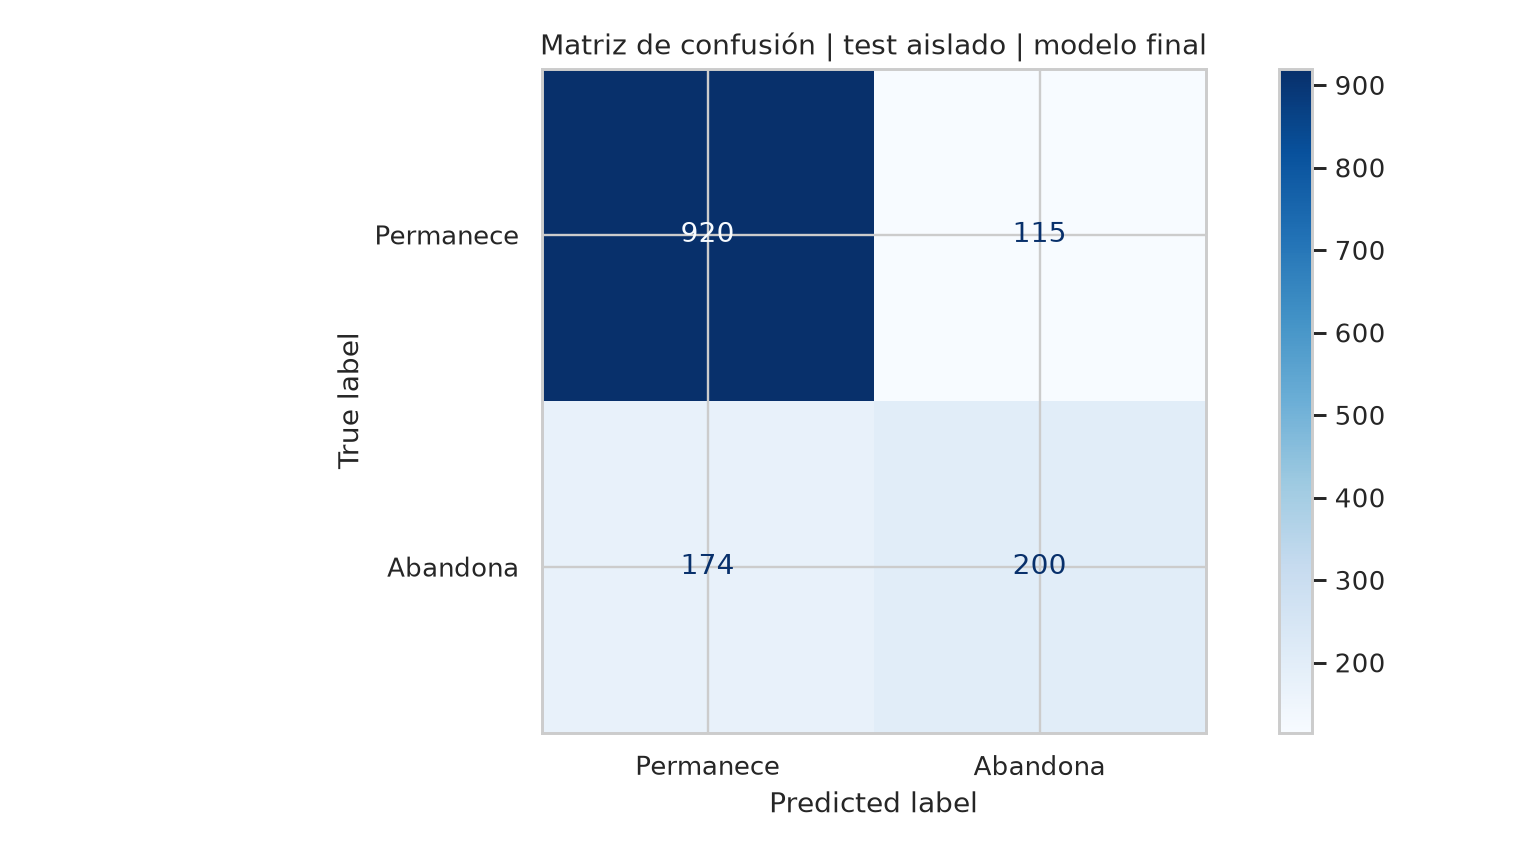

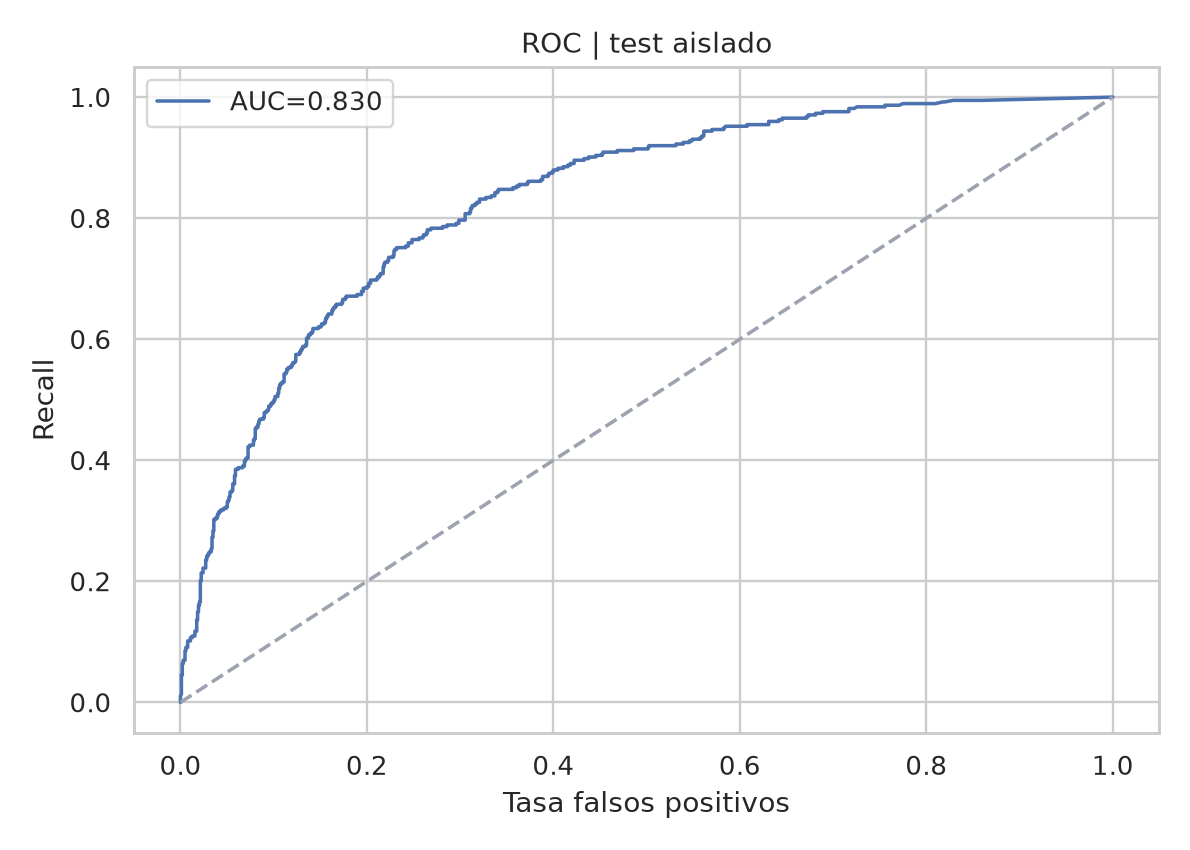

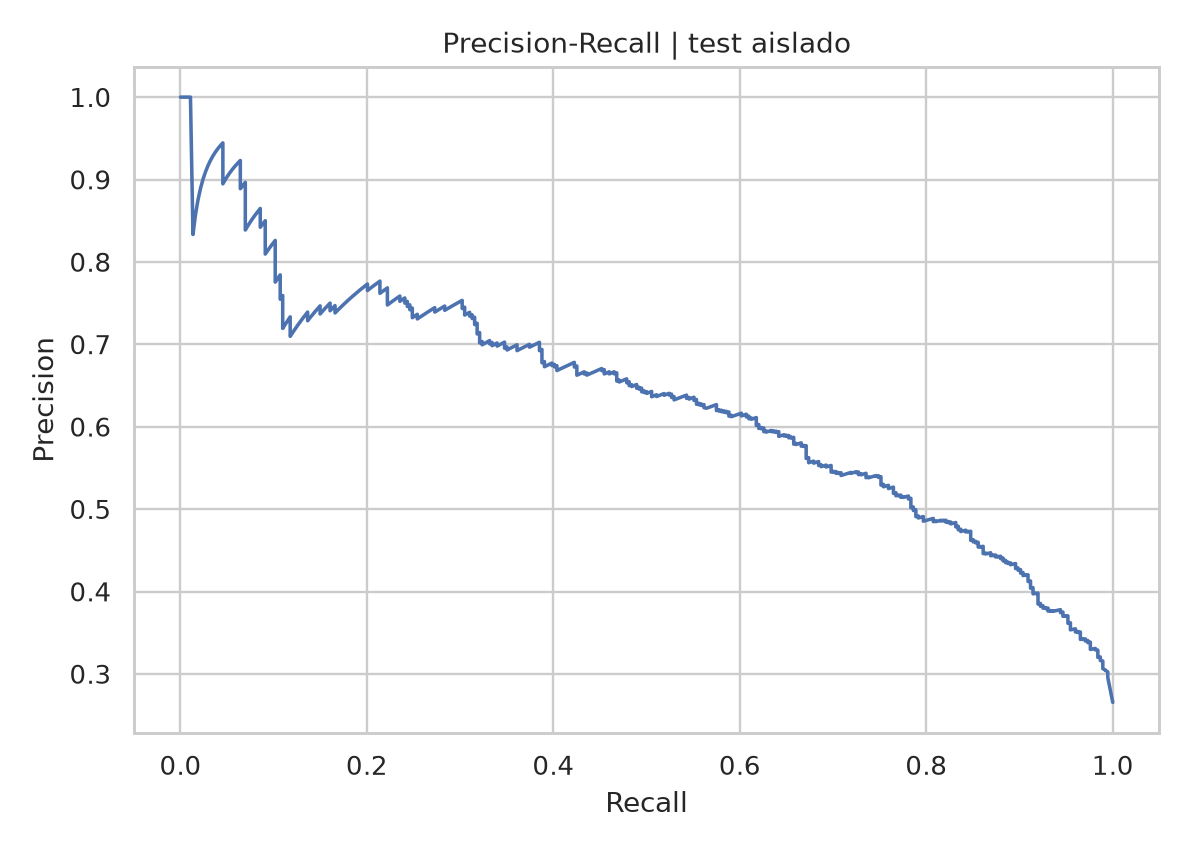

In [21]:
metrics=read_json('metricas_test_final.json')
rows=[]
for name,m in metrics.items():
    rows.append({'Modelo':name,**{key:m[key] for key in ('accuracy','precision','recall','f1','roc_auc','average_precision')}})
display(pd.DataFrame(rows).set_index('Modelo').round(4))
print('Matriz de confusión del modelo final (TN,FP / FN,TP):')
print(np.array(metrics['modelo_final']['matriz_confusion']))
for name in ('matriz_confusion_test.png','roc_test.png','pr_test.png'):
    display(Image(filename=str(FIG/name)))


# Parte 2 · Hyperparameter Optimization

Se optimiza **el mismo Random Forest**, con idéntico esquema `ColumnTransformer`
+ `Pipeline`, tres folds estratificados fijos y F1 como objetivo.

- **Grid Search:** recorre exhaustivamente la cuadrícula de 16 combinaciones.
- **Random Search:** evalúa 16 configuraciones aleatorias de un espacio más amplio.
- **Hyperband (Optuna):** combina múltiples asignaciones de recursos y parada
  anticipada (*early stopping*). Cada configuración aumenta de **20 → 60 → 180 árboles**,
  con `warm_start`, permitiendo suspender aquellas que no justifican más cómputo.
  Optuna implementa Hyperband con un `HyperbandPruner` y `RandomSampler`.

**Comparabilidad:** los tres métodos proponen 16 configuraciones y usan los mismos folds,
pero Grid Search utiliza una cuadrícula más estrecha. Hyperband usa presupuestos
*incrementales*, de modo que el número de configuraciones plenamente evaluadas,
los árboles construidos y el tiempo total **no son idénticos**. Se reportan ambos
presupuestos para evitar comparaciones engañosas.


In [22]:
from src.experiments import GRID, GLOBAL
from sklearn.model_selection import ParameterGrid
space = pd.DataFrame({
    'Hiperparámetro': [key.removeprefix('modelo__') for key in GRID],
    'Grid Search': [str(values) for values in GRID.values()],
    'Random Search / NSGA-II': [str(GLOBAL[key]) for key in GRID],
    'Hyperband': [
        'Recurso: 20, 60, 180 árboles (máximo 180)',
        str(GLOBAL['modelo__max_depth']),
        str(GLOBAL['modelo__min_samples_leaf']),
        str(GLOBAL['modelo__max_features'])]
})
display(space)
print('Grid Search:', len(ParameterGrid(GRID)), 'combinaciones.')
print('CV: StratifiedKFold(n_splits=3, shuffle=True, random_state=42).')


,Hiperparámetro,Grid Search,Random Search / NSGA-II,Hyperband
0,n_estimators,"[60, 180]","[40, 60, 80, 100, 120, 160, 180]","Recurso: 20, 60, 180 árboles (máximo 180)"
1,max_depth,"[6, 14]","[4, 6, 8, 10, 14, 20, None]","[4, 6, 8, 10, 14, 20, None]"
2,min_samples_leaf,"[1, 4]","[1, 2, 3, 4, 6]","[1, 2, 3, 4, 6]"
3,max_features,"['sqrt', 0.75]","['sqrt', 0.5, 0.75]","['sqrt', 0.5, 0.75]"


Grid Search: 16 combinaciones.
CV: StratifiedKFold(n_splits=3, shuffle=True, random_state=42).


In [23]:
search=pd.read_csv(ART/'comparacion_optimizadores_cv.csv')
cols=['estrategia','f1_cv','recall_cv','roc_auc_cv','tiempo_busqueda_s',
      'evaluaciones','configuraciones_completas','configuraciones_podadas',
      'recurso_total_arboles_por_fold','equivalentes_180_arboles']
display(search[cols].round(4))
print('La mejor estrategia por F1 de CV es:',
      search.loc[search['f1_cv'].idxmax(), 'estrategia'])


,estrategia,f1_cv,recall_cv,roc_auc_cv,tiempo_busqueda_s,evaluaciones,configuraciones_completas,configuraciones_podadas,recurso_total_arboles_por_fold,equivalentes_180_arboles
0,Grid Search,0.5721,0.5017,0.8466,29.8770,16,16,0,1920,10.6667
1,Random Search,0.5736,0.4977,0.8461,20.7503,16,16,0,1620,9.0000
2,Hyperband (Optuna),0.5736,0.4977,0.8461,23.1692,16,8,8,1720,9.5556


La mejor estrategia por F1 de CV es: Random Search


,estrategia,evaluacion,f1_cv,estado,recurso_arboles,es_evaluacion_completa
0,Grid Search,1,0.5547,COMPLETE,60,True
1,Grid Search,2,0.5499,COMPLETE,180,True
2,Grid Search,3,0.5479,COMPLETE,60,True
3,Grid Search,4,0.5478,COMPLETE,180,True
4,Grid Search,5,0.5699,COMPLETE,60,True
5,Grid Search,6,0.5661,COMPLETE,180,True
6,Grid Search,7,0.5674,COMPLETE,60,True
7,Grid Search,8,0.5721,COMPLETE,180,True
8,Grid Search,9,0.5452,COMPLETE,60,True
9,Grid Search,10,0.5537,COMPLETE,180,True


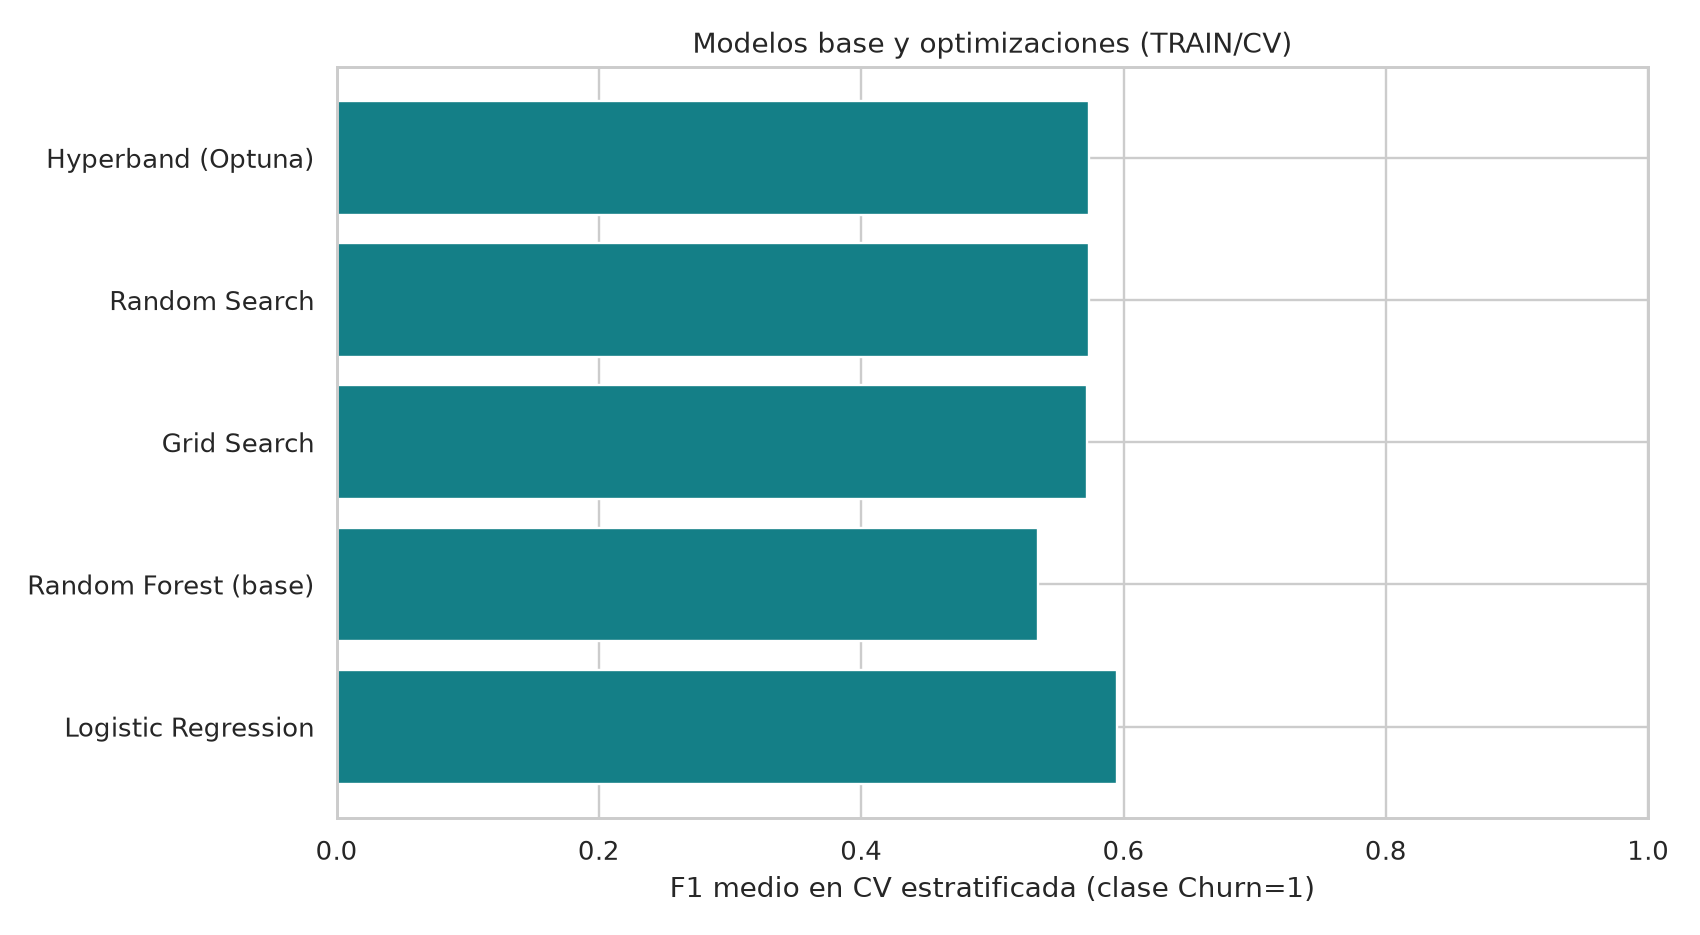

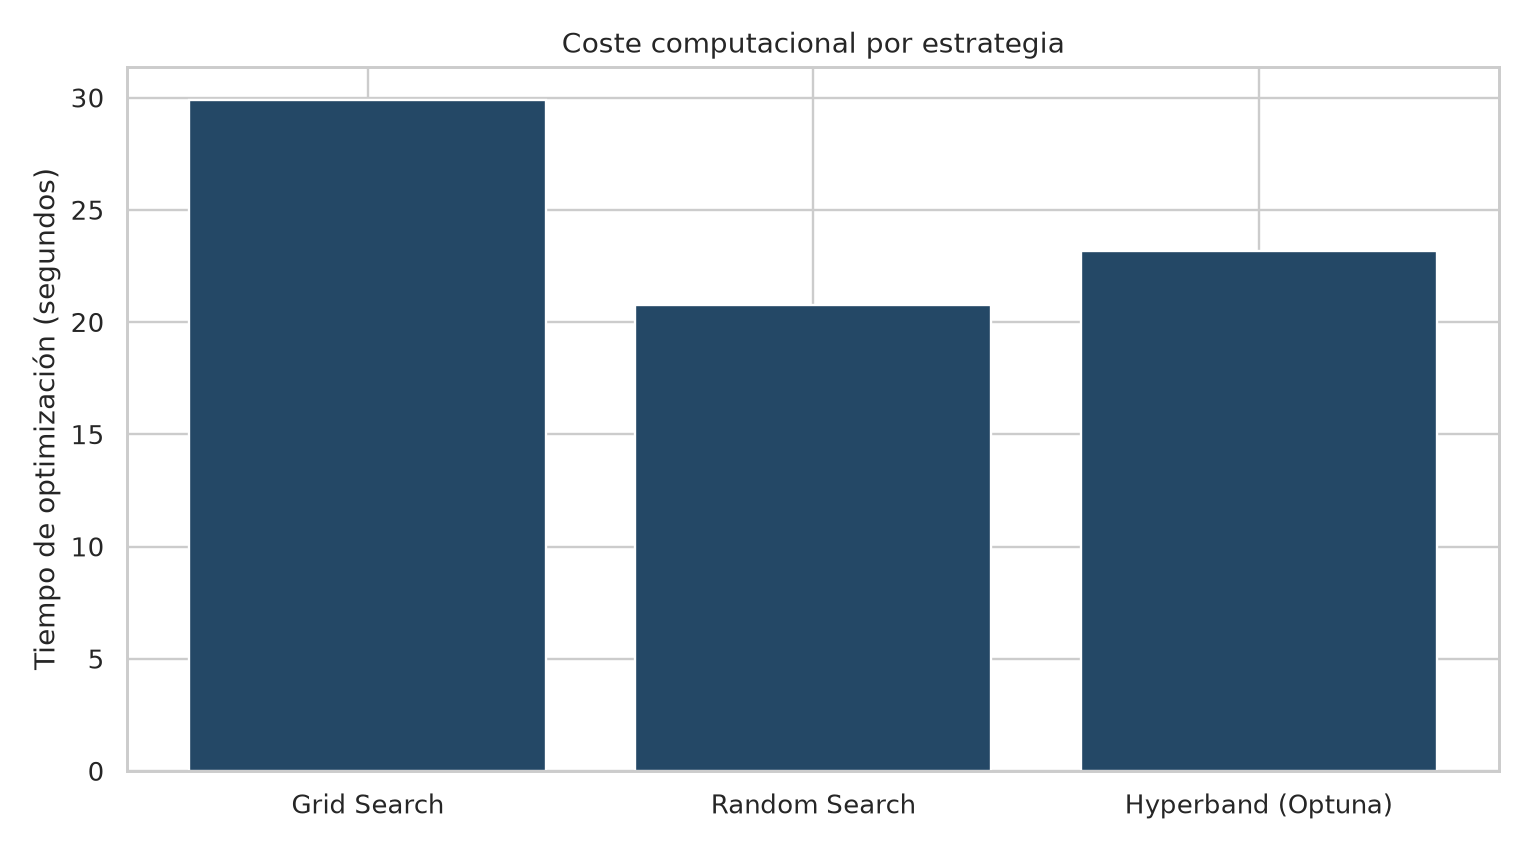

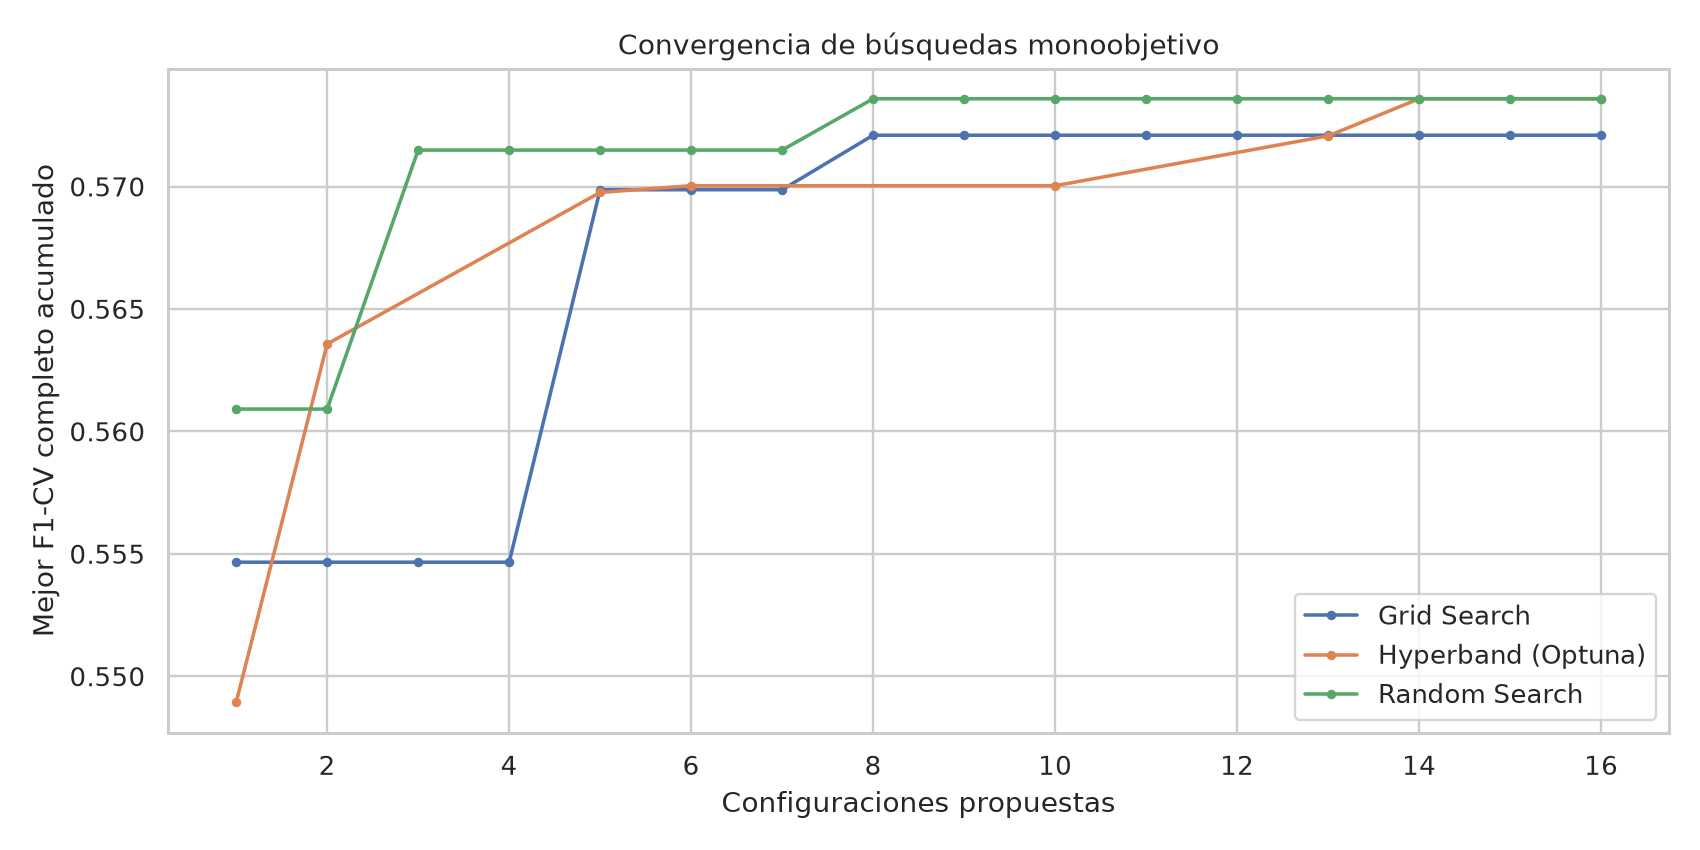

In [24]:
history=pd.read_csv(ART/'historial_busquedas.csv')
display(history[[c for c in ('estrategia','evaluacion','f1_cv',
    'estado','recurso_arboles','es_evaluacion_completa') if c in history.columns]].head(30).round(4))
for name in ('comparacion_f1_cv.png','tiempos_optimizacion.png','convergencia_busqueda.png'):
    display(Image(filename=str(FIG/name)))


# Parte 3 · Multiobjective Optimization: NSGA-II

**Maximizamos la calidad** y **minimizamos el tiempo de inferencia** del pipeline
completo sobre los mismos folds de TRAIN:

$$\max_{\theta}f_1(\theta)=\frac{1}{3}\sum_{k=1}^{3}F1_k(\theta),$$

$$\min_{\theta}f_2(\theta)=\operatorname{mediana}_k\left[
\frac{1000 T_{\mathrm{pred},k}(\theta)}{n_{\mathrm{clientes},k}}
\right]\quad[\mathrm{ms/cliente}].$$

La latencia tiene calentamiento previo, cinco repeticiones por fold y hasta 128 clientes
por lote. No corresponde al tiempo de entrenamiento y depende del hardware.

Un punto es **no dominado** si no hay otra solución que mejore o empate ambos
objetivos y mejore estrictamente al menos uno. La regla previa al test acepta
soluciones a ≤0,01 puntos del mejor F1 Pareto para escoger menor latencia, y
prefiere dicha solución si está a ≤0,015 puntos del mejor Random Forest monoobjetivo.


Opciones NSGA-II: 16  | Frente Pareto: 4


,trial,f1_cv,latencia_ms_cliente,roc_auc_cv
0,2,0.57000,0.11679,0.84725
1,5,0.56968,0.07969,0.84341
2,14,0.56520,0.06090,0.83155
3,7,0.56083,0.05747,0.83171


Solución Pareto propuesta: {'trial': 7, 'f1_cv': 0.5608315405934453, 'latencia_ms_cliente': 0.057471859378210866, 'params': {'modelo__max_depth': 14, 'modelo__max_features': 0.5, 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 40}, 'tiempo_busqueda_s': 19.884347833998618, 'evaluaciones': 16, 'poblacion': 8, 'criterio': 'F1 dentro de 0.01 del máximo de Pareto; escoger menor latencia (desempate F1).'}
MODELO OPERATIVO SELECCIONADO POR CV: {'nombre': 'NSGA-II (Pareto)', 'params': {'modelo__max_depth': 14, 'modelo__max_features': 0.5, 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 40}, 'f1_cv': 0.5608315405934453, 'motivo': 'F1 a menos de 0.015 del mejor RF y menor latencia elegible en Pareto.'}


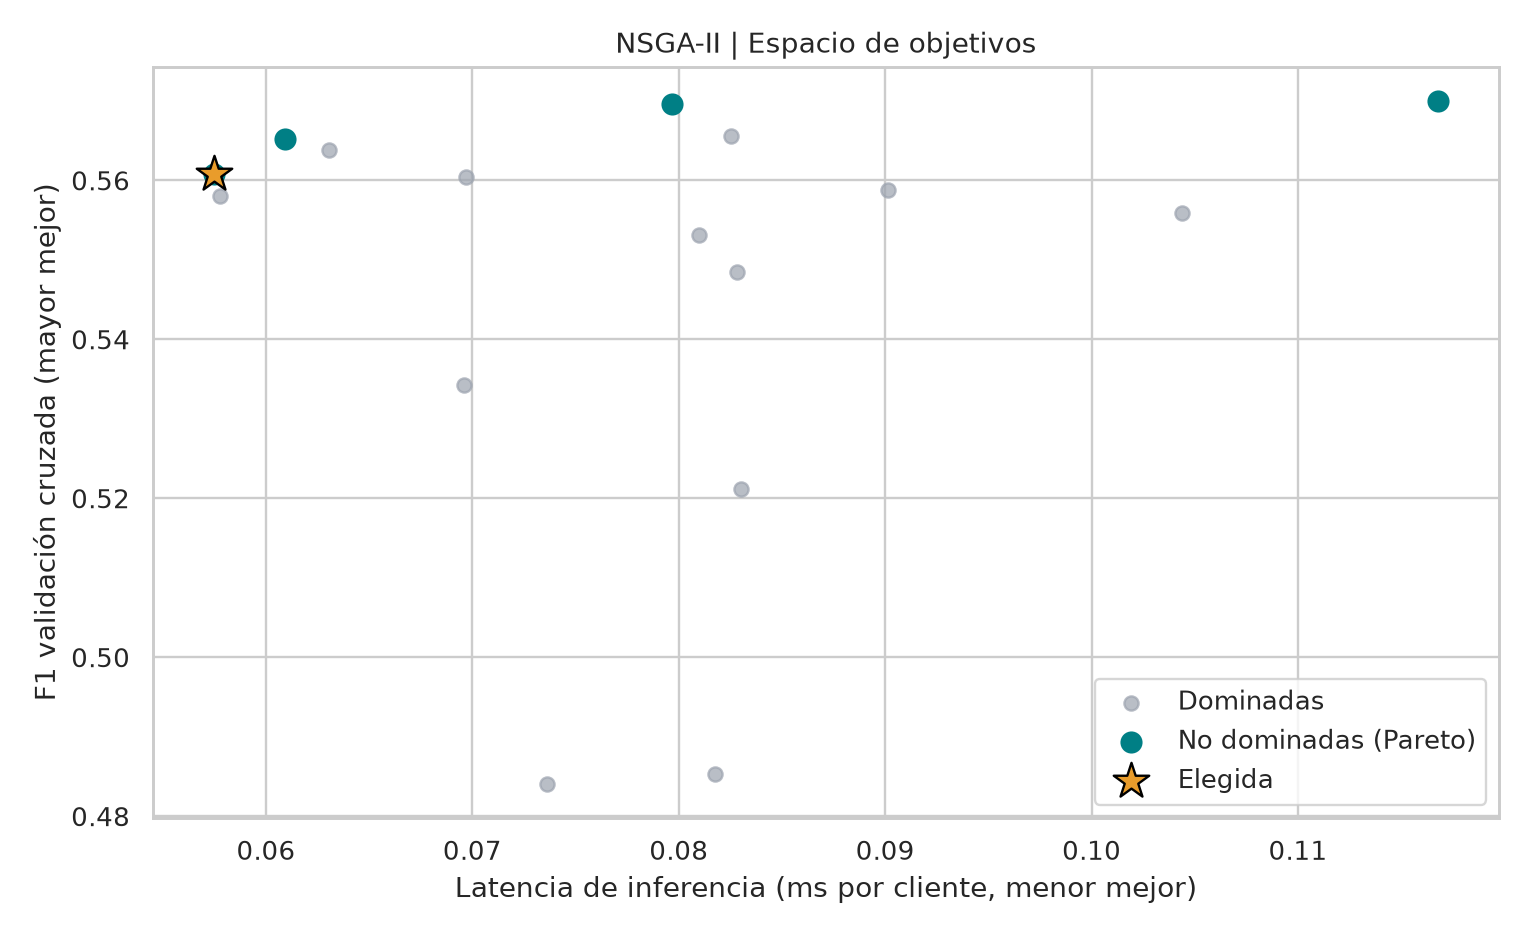

In [25]:
all_nsga=pd.read_csv(ART/'nsga_todos.csv')
pareto=pd.read_csv(ART/'frente_pareto.csv')
choice=read_json('seleccion_pareto.json')
selection=read_json('seleccion_modelo_final.json')
print('Opciones NSGA-II:',len(all_nsga),' | Frente Pareto:',len(pareto))
display(pareto[['trial','f1_cv','latencia_ms_cliente','roc_auc_cv']].round(5))
print('Solución Pareto propuesta:', choice)
print('MODELO OPERATIVO SELECCIONADO POR CV:',selection)
display(Image(filename=str(FIG/'frente_pareto.png')))


# Parte 4 · Explainable AI: SHAP, LIME y Feature Importance

**SHAP global** mide la contribución media absoluta de características originales
(agregación de One-Hot). **SHAP local** suma contribuciones respecto de una
probabilidad base para explicar `P(Churn=1)`.

**LIME local** perturba las variables originales, incluida la codificación de
categorías, y aproxima el comportamiento alrededor del cliente. Se explica a
**los mismos dos perfiles** para las dos técnicas: mayor y menor riesgo estimado
en el holdout. La elección no utiliza la etiqueta real del cliente.

**Random Forest Feature Importance** utiliza reducción media de impureza; puede
favorecer determinadas características y no proporciona dirección causal.
Ninguna de estas técnicas demuestra que cambiar un atributo evite bajas.


,Variable,SHAP_importancia_abs_media
0,Contract,0.1199
1,tenure,0.0497
2,OnlineSecurity,0.0453
3,InternetService,0.0447
4,TotalCharges,0.0362
5,TechSupport,0.0348
6,MonthlyCharges,0.0342
7,PaymentMethod,0.0267
8,PaperlessBilling,0.0155
9,MultipleLines,0.0123


,Variable,RandomForest_importancia_impureza
0,Contract,0.1678
1,TotalCharges,0.1636
2,MonthlyCharges,0.1526
3,tenure,0.1278
4,OnlineSecurity,0.0682
5,TechSupport,0.0482
6,PaymentMethod,0.0465
7,InternetService,0.0388
8,gender,0.0254
9,PaperlessBilling,0.0231


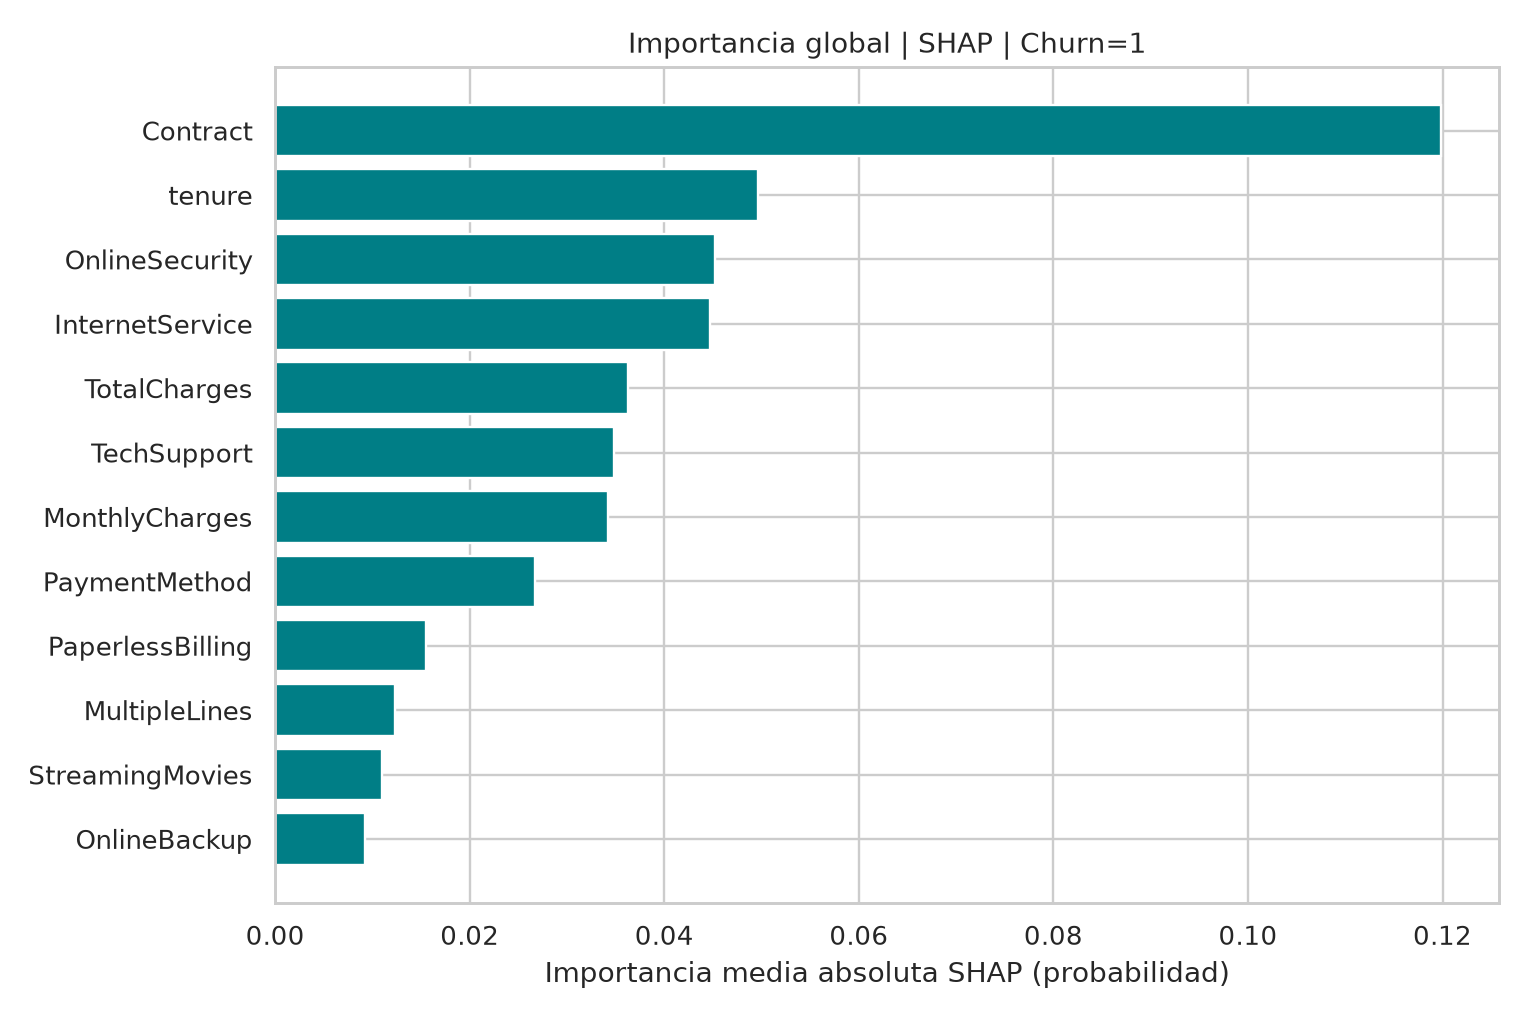

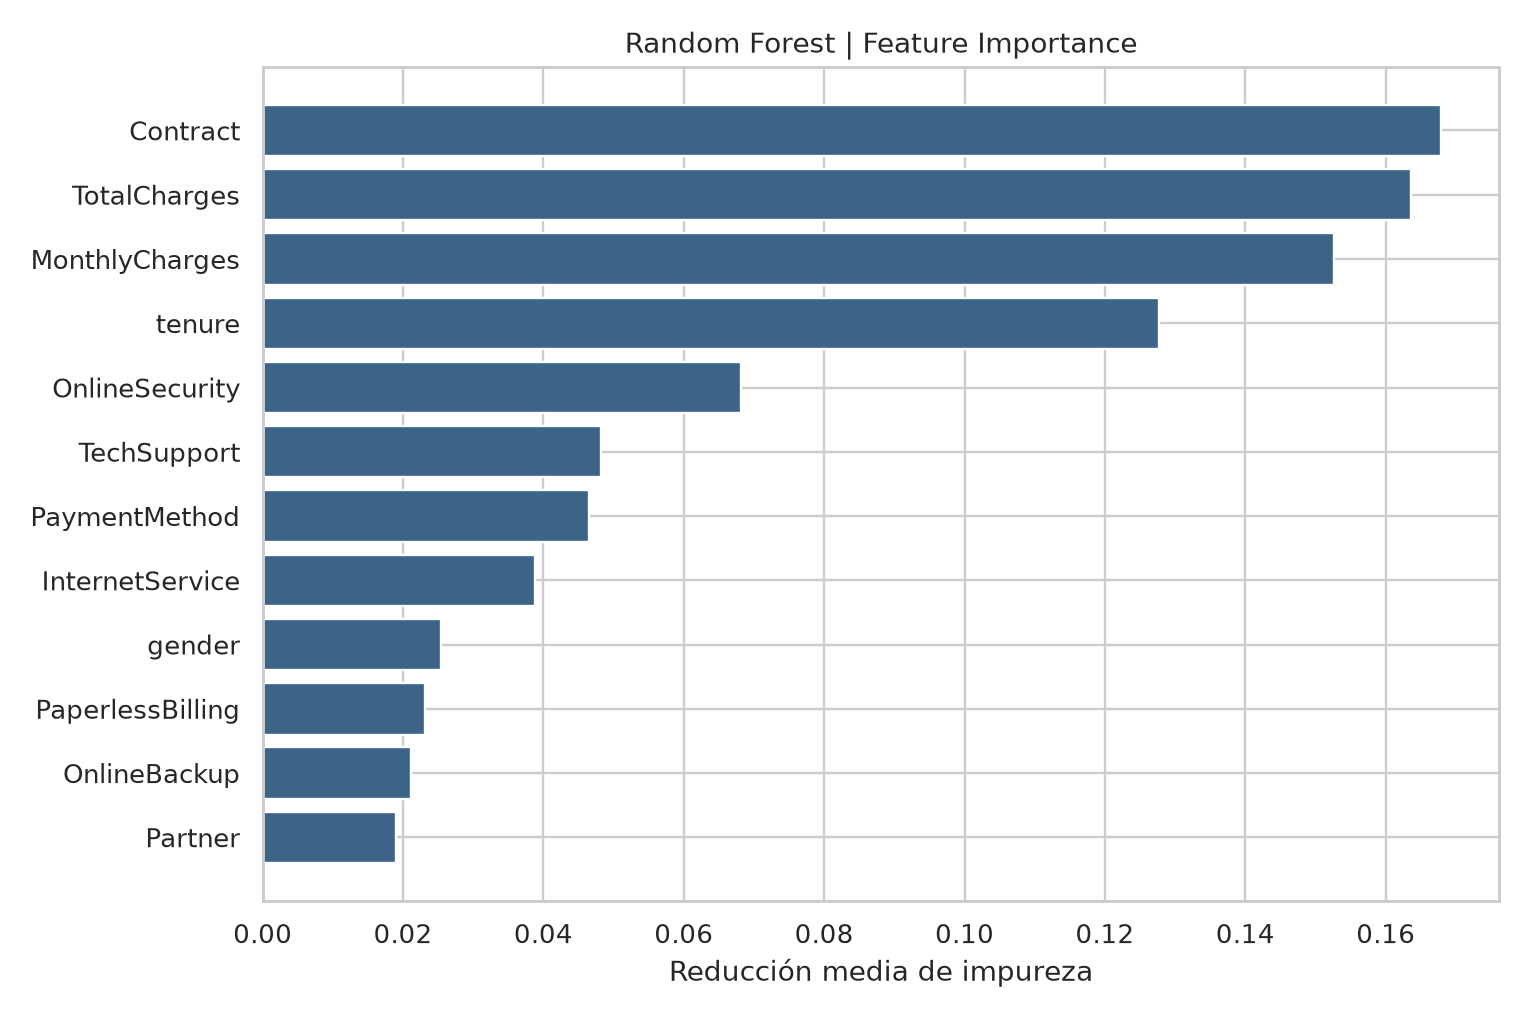

In [26]:
shap=pd.read_csv(ART/'shap_global.csv')
fi=pd.read_csv(ART/'rf_feature_importance.csv')
display(shap.head(10).round(4))
display(fi.head(10).round(4))
for name in ('shap_global.png','rf_feature_importance.png'):
    display(Image(filename=str(ART/name)))


,cliente,indice_original,probabilidad,base_shap,shap_residual
0,1,809,0.99902,0.266143,2.220446e-16
1,2,5082,0.00000,0.266143,2.220446e-16


### Cliente 1: SHAP y LIME

,feature,SHAP_churn_1
0,num__TotalCharges,0.177161
1,cat__Contract_Month-to-month,0.153954
2,num__tenure,0.149263
3,cat__OnlineSecurity_No,0.063721
4,cat__InternetService_Fiber optic,0.048191
5,cat__TechSupport_No,0.047058
6,cat__PaymentMethod_Electronic check,0.025866
7,num__MonthlyCharges,0.016234


,regla_lime,peso_lime_churn_1
0,Contract=Month-to-month,0.162166
1,tenure <= 9.00,0.104297
2,InternetService=Fiber optic,0.077107
3,TotalCharges <= 402.98,0.061478
4,TechSupport=No,0.058846
5,OnlineSecurity=No,0.057554
6,PaymentMethod=Electronic check,0.038320
7,SeniorCitizen=No,-0.037851


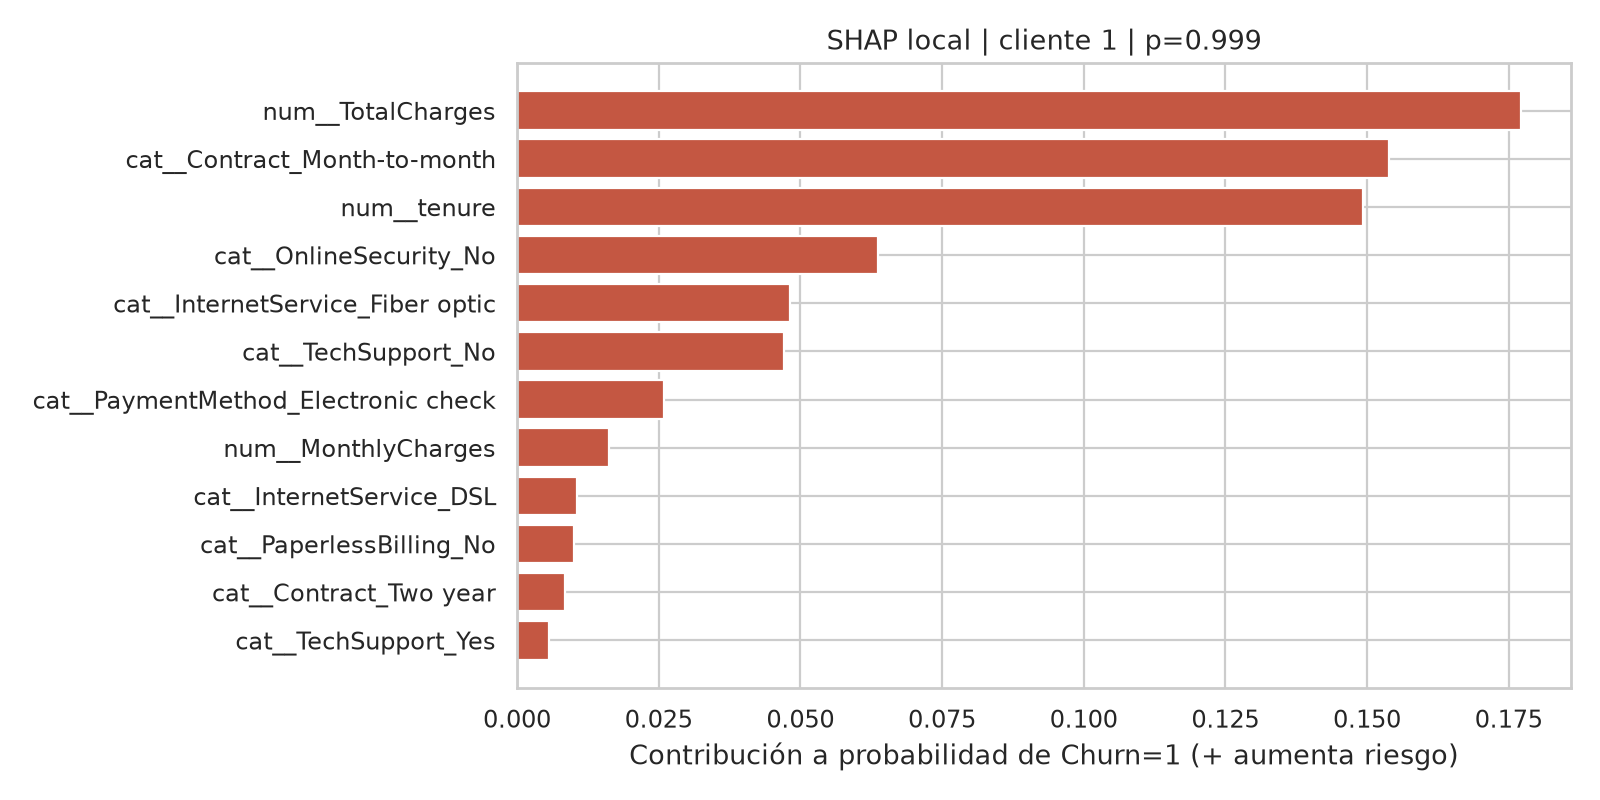

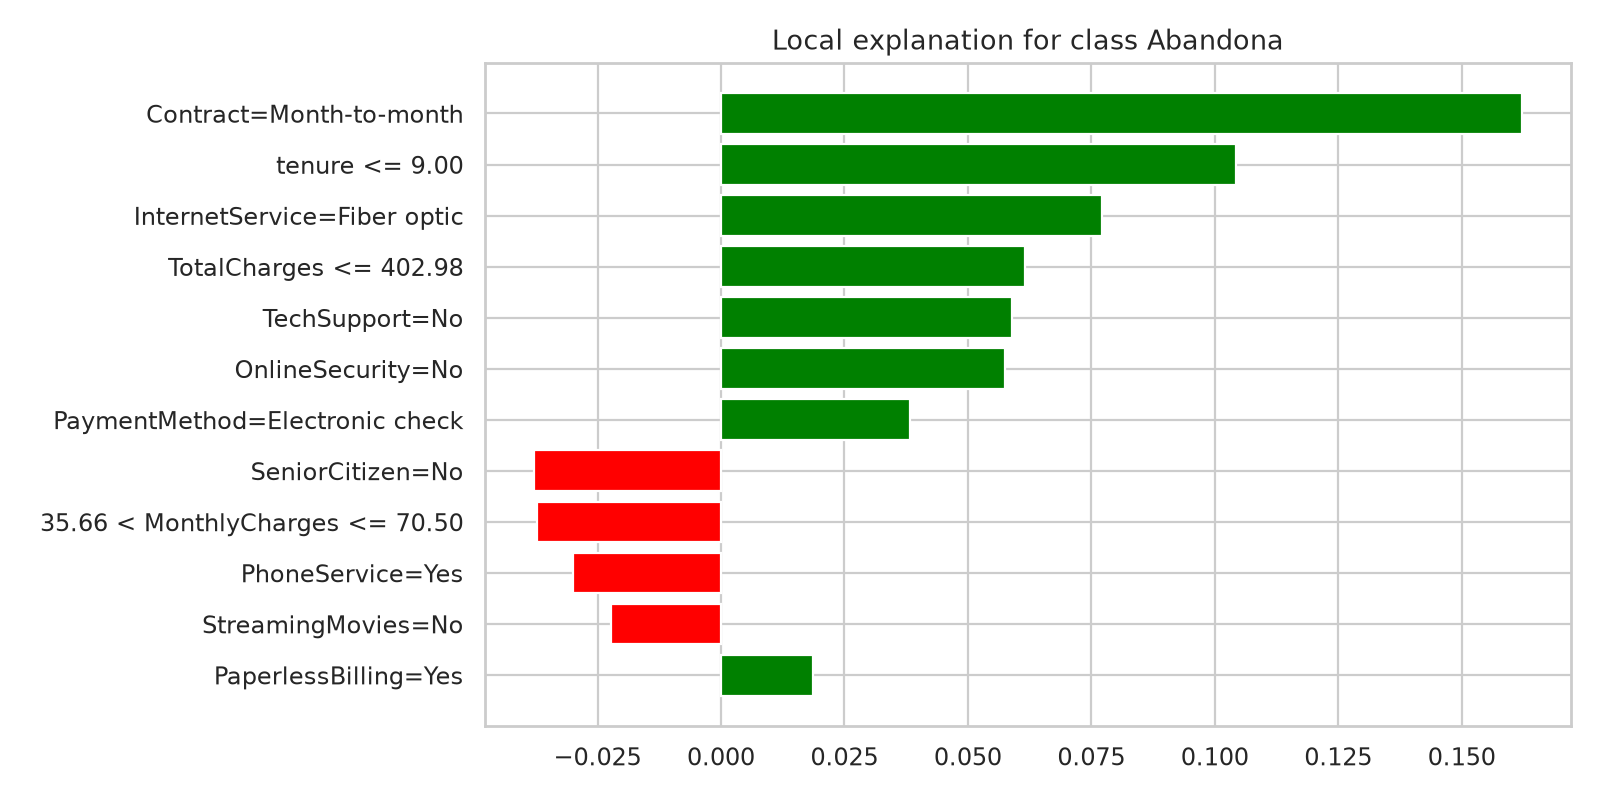

### Cliente 2: SHAP y LIME

,feature,SHAP_churn_1
0,cat__Contract_Month-to-month,-0.073779
1,cat__OnlineSecurity_No,-0.054689
2,cat__TechSupport_No,-0.039165
3,num__MonthlyCharges,-0.030701
4,cat__InternetService_Fiber optic,-0.021213
5,num__tenure,-0.013808
6,num__TotalCharges,0.012042
7,cat__PaymentMethod_Electronic check,-0.010878


,regla_lime,peso_lime_churn_1
0,Contract=One year,-0.065076
1,TotalCharges <= 402.98,0.045991
2,TechSupport=No internet service,-0.032625
3,OnlineSecurity=No internet service,-0.025832
4,InternetService=No,-0.024977
5,PaymentMethod=Mailed check,-0.024492
6,PaperlessBilling=No,-0.019766
7,DeviceProtection=No internet service,-0.018618


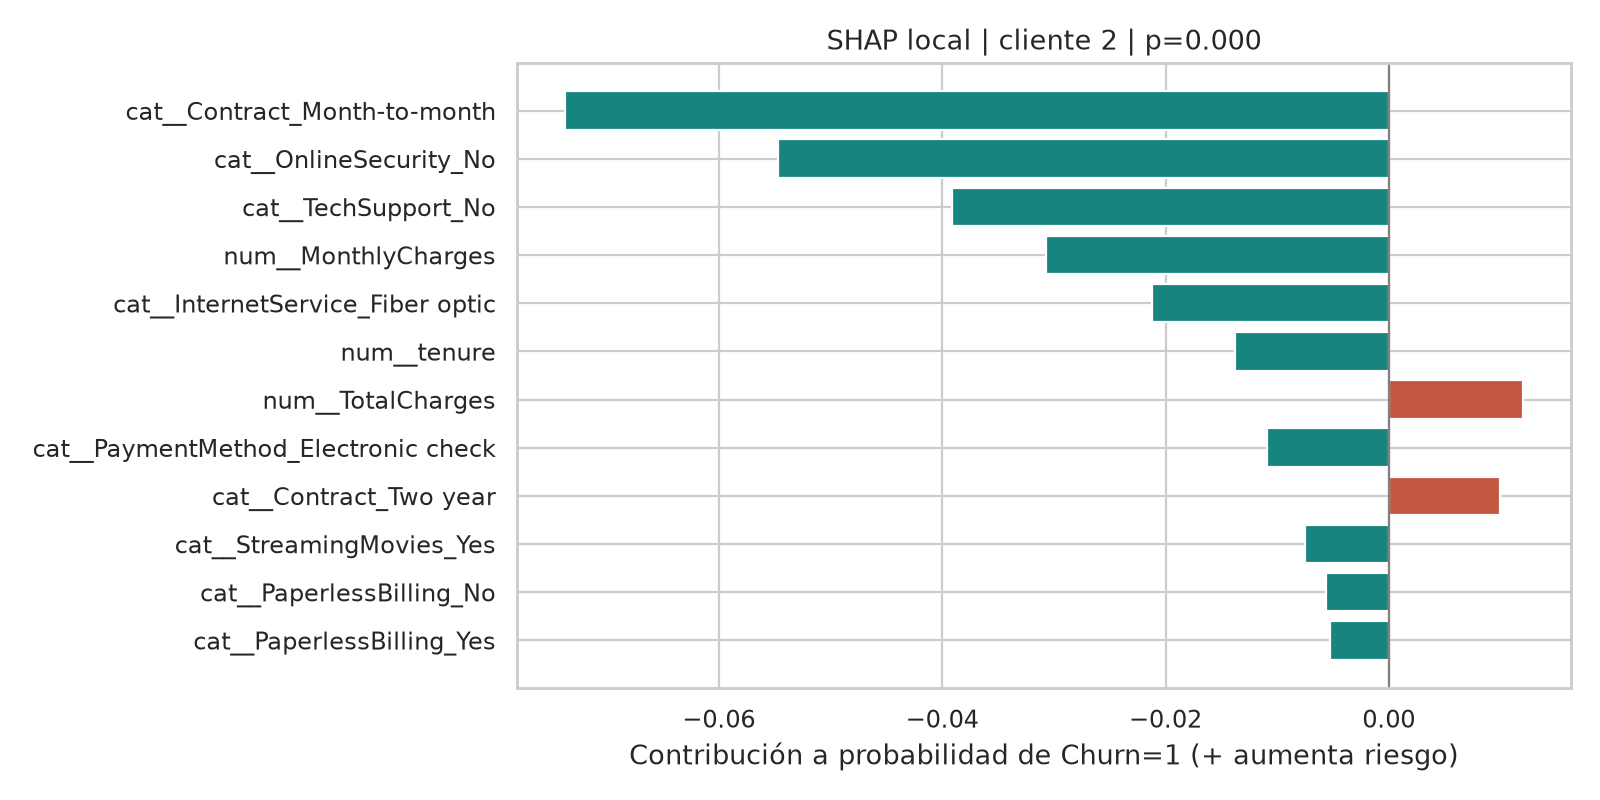

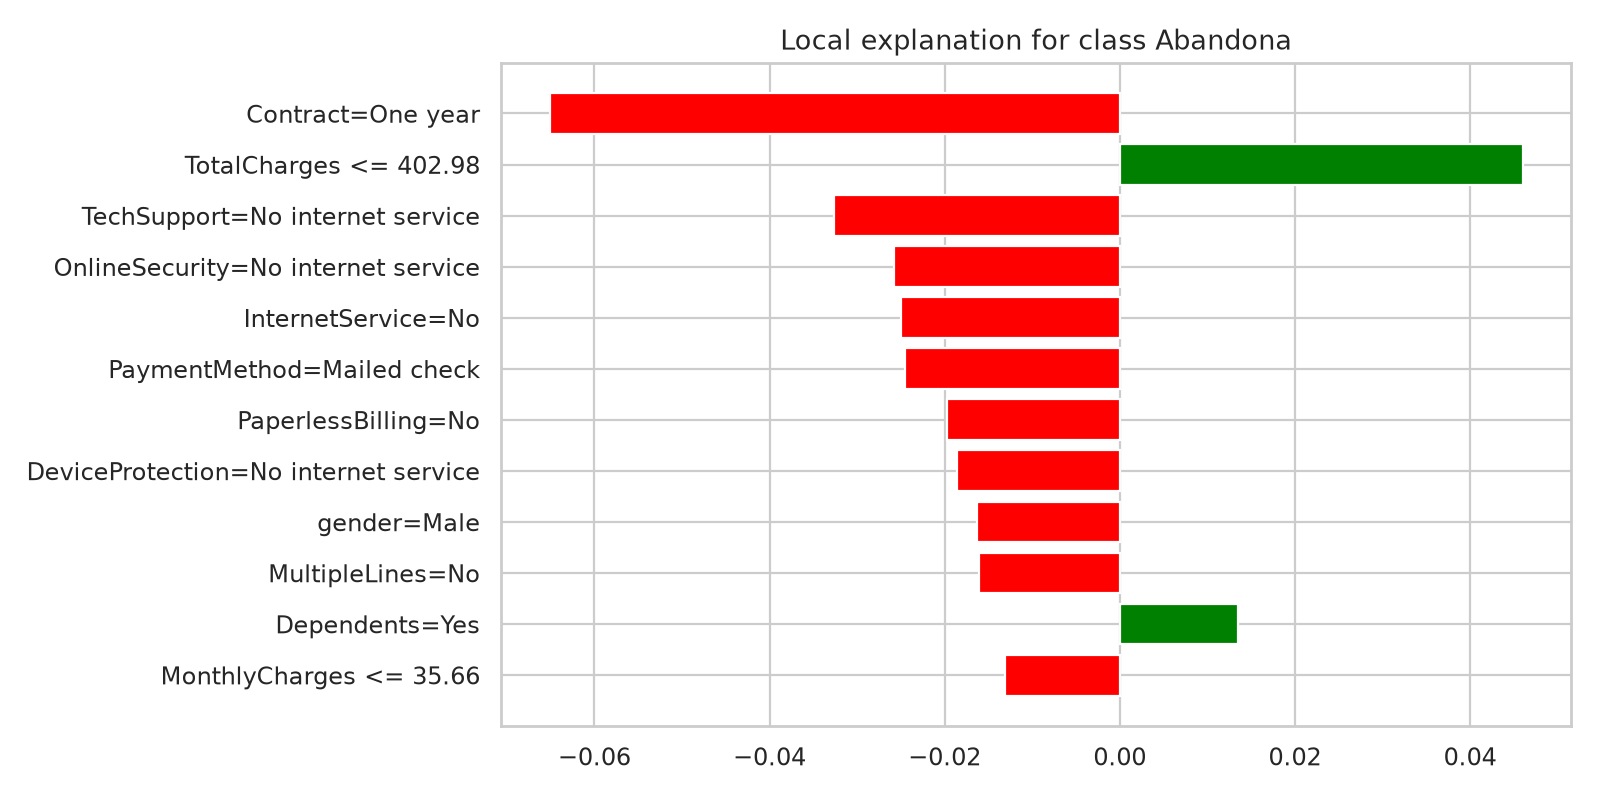

In [27]:
examples=read_json('explicaciones_clientes.json')
display(pd.DataFrame(examples)[['cliente','indice_original','probabilidad','base_shap','shap_residual']])
for i in (1,2):
    display(Markdown(f'### Cliente {i}: SHAP y LIME'))
    display(pd.read_csv(ART/f'shap_cliente_{i}.csv').head(8))
    display(pd.read_csv(ART/f'lime_cliente_{i}.csv').head(8))
    display(Image(filename=str(ART/f'shap_cliente_{i}.png')))
    display(Image(filename=str(ART/f'lime_cliente_{i}.png')))


# Parte 5 · Streamlit

`app.py` es el producto comercial FaroCX. Integra **Exploratory Data Analysis**
(con visualizaciones, KPIs y filtros), **Model Performance**, **Hyperparameter
Optimization**, **NSGA-II · Pareto Frontier**, **Explainable AI · SHAP y LIME**,
**Prediction & Explainability** y **Business Application**.

La aplicación **no entrena**; carga pipelines `.joblib`, métricas y gráficos exportados.
El público no ve instrucciones de clase, un guion de exposición ni controles internos.
Para ejecutarla desde el directorio raíz: `python -m streamlit run app.py`.


# Parte 6 · Propuesta comercial FaroCX

**Problema:** una operadora tiene recursos limitados para contactar a clientes,
pero el abandono provoca pérdida potencial de margen.

**Producto y comprador:** FaroCX es una plataforma de riesgo, explicación y
priorización de campañas para gerencias de CRM/retención.

**Diferenciadores:** auditoría reproducible, Grid Search, Random Search,
Hyperband, NSGA-II, explicaciones SHAP/LIME y simulación de presupuesto.

**Monetización propuesta:** licencia hipotética de **USD 59/mes** más servicios
de integración, cuyos costos reales aún deben cotizarse.

**Valor neto esperado bajo hipótesis** por cliente:

$$V_i=p_i\,e\,M_i\,m\,H-c_i,$$

donde $p_i$ es el riesgo predicho, $e$ eficacia incremental **no medida**,
$M_i$ mensualidad, $m$ margen hipotético, $H$ meses y $c_i$ costo de contacto.
La suma del escenario considera también la licencia.

**Riesgos:** sesgo, privacidad, deriva temporal, datos no representativos,
latencia variable y coste de falsos negativos/falsos positivos. Una prueba
**A/B** mediría el efecto incremental real de las campañas antes de escalar.


In [28]:
economics=read_json('escenario_comercial_hipotetico.json')
display(pd.DataFrame([economics]).T.rename(columns={0:'Valor del escenario (hipotético)'}))
print('No corresponde a ROI causal estimado; se basa en supuestos editables.')


,Valor del escenario (hipotético)
contactados,62
costo_acciones_usd,496.0
costo_software_usd,59.0
beneficio_bruto_esperado_usd,2068.310861
resultado_neto_hipotetico_usd,1513.310861
roi_hipotetico,2.726686
eficacia_minima_break_even,0.04025
advertencia,Supuestos no causales: sin ensayo A/B NO hay evidencia de uplift ni retorno real.


No corresponde a ROI causal estimado; se basa en supuestos editables.


# Entrega y Business Pitch

- Notebook reproducible con celdas de EDA original y evidencias experimentales.
- Modelos exportados, código y `requirements.txt` para repositorio GitHub.
- Streamlit comercial funcionando y enlace público comprobado antes de Moodle.
- Beamer/LaTeX: **máximo cinco diapositivas, fondo claro y sin código**.
- Negociación presencial: 2 minutos de propuesta/demostración, 2 minutos de
  preguntas y 1 minuto de cierre. El turno como comprador también se evalúa.

**Observación científica:** el resultado independiente puede favorecer a
Logistic Regression incluso si el seleccionado por CV/NSGA-II es Random Forest.
No debe reemplazarse el modelo después de ver TEST: se informa la diferencia.


In [29]:
# Crear PDF Beamer desde los resultados de esta ejecución; requiere pdflatex instalado.
from build_pitch import main as generate_pitch
generate_pitch()
print('Revisar las cinco diapositivas y ejecutar python VALIDAR_ENTREGA.py.')


Fuente LaTeX generada: /home/kevin-erazo/OneDrive/8) Octavo Semestre/Aprendizaje Automatico/7. Optimización de Machine Learning, Explainable AI y Business Pitch/V2/Pitch_RetenIA_Kevin_Erazo.tex
PDF generado (5 diapositivas): /home/kevin-erazo/OneDrive/8) Octavo Semestre/Aprendizaje Automatico/7. Optimización de Machine Learning, Explainable AI y Business Pitch/V2/Pitch_RetenIA_Kevin_Erazo.pdf
Revisar las cinco diapositivas y ejecutar python VALIDAR_ENTREGA.py.


In [30]:
# Conclusiones generadas con las MÉTRICAS REALES de la nueva ejecución.
final=metrics['modelo_final']
logit=metrics['logistic_regression_baseline']
best=search.sort_values('f1_cv',ascending=False).iloc[0]
print(f"Modelo seleccionado antes del holdout: {selection['nombre']} (F1-CV={selection['f1_cv']:.4f}).")
print(f"Test final: Accuracy={final['accuracy']:.4f}; Precision={final['precision']:.4f}; "
      f"Recall={final['recall']:.4f}; F1={final['f1']:.4f}; ROC-AUC={final['roc_auc']:.4f}.")
print(f"Mejor optimización monoobjetivo: {best['estrategia']} (F1-CV={best['f1_cv']:.4f}).")
print(f"Logistic Regression test: F1={logit['f1']:.4f}; compararlo honestamente con el modelo final.")
print('SHAP top-3:', ', '.join(shap['Variable'].head(3)))
print('Límites: los factores no son causas y el ROI comercial es un escenario hipotético.')


Modelo seleccionado antes del holdout: NSGA-II (Pareto) (F1-CV=0.5608).
Test final: Accuracy=0.7949; Precision=0.6349; Recall=0.5348; F1=0.5806; ROC-AUC=0.8299.
Mejor optimización monoobjetivo: Random Search (F1-CV=0.5736).
Logistic Regression test: F1=0.6040; compararlo honestamente con el modelo final.
SHAP top-3: Contract, tenure, OnlineSecurity
Límites: los factores no son causas y el ROI comercial es un escenario hipotético.
